# Install Library

In [ ]:
#Install Package
install.packages("timeSeries")
install.packages("tseries")
install.packages("forecast")
install.packages("ggplot2")
install.packages("TSstudio")
install.packages("lmtest")
install.packages("keras")
install.packages("tensorflow")
install.packages("quantmod")
install.packages("rugarch")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘timeDate’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘fracdiff’, ‘lmtest’, ‘Rcpp’, ‘urca’, ‘RcppArmadillo’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘SparseM’, ‘RcppEigen’, ‘hts’, ‘iterators’, ‘later’, ‘BH’, ‘thief’, ‘doParallel’, ‘foreach’, ‘htmlwidgets’, ‘lazyeval’, ‘crosstalk’, ‘promises’, ‘plyr’, ‘anytime’, ‘gridExtra’, ‘forecastHybrid’, ‘plotly’, ‘reshape2’, ‘tsibble’, ‘viridis’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing packag

In [ ]:
# install library
library(timeSeries)
library(tseries)
library(forecast)
library(ggplot2)
library(TSstudio)
library(quantmod)


Loading required package: timeDate


Attaching package: ‘timeSeries’


The following objects are masked from ‘package:graphics’:

    lines, points


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

Loading required package: xts

Loading required package: zoo


Attaching package: ‘zoo’


The following object is masked from ‘package:timeSeries’:

    time<-


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: TTR



# Ambil Data Harga Kurs USD to IDR

In [ ]:
df <- getSymbols("IDR=X",src="yahoo",from="2015-01-01",to = "2024-04-29", auto.assign = FALSE)

Warning message:
“IDR=X contains missing values. Some functions will not work if objects contain missing values in the middle of the series. Consider using na.omit(), na.approx(), na.fill(), etc to remove or replace them.”


In [ ]:
df

           IDR.X.Open IDR.X.High IDR.X.Low IDR.X.Close IDR.X.Volume
2015-01-01    12390.0    12390.0   12390.0     12390.0            0
2015-01-02    12435.0    12550.0   12397.0     12390.0            0
2015-01-05    12535.0    12685.0   12430.0     12480.0            0
2015-01-06    12630.0    12675.0   12580.0     12625.0            0
2015-01-07    12695.0    12755.0   12415.0     12635.0            0
2015-01-08    12700.0    12750.0   12605.0     12720.0            0
2015-01-09    12630.0    12645.0   12505.0     12610.0            0
2015-01-12    12565.0    12605.0   12535.0     12565.0            0
2015-01-13    12580.0    12620.0   12507.0     12558.0            0
2015-01-14    12565.0    12635.0   12564.0     12587.0            0
       ...                                                         
2024-04-15    16075.0    16309.4   15853.5     16075.0            0
2024-04-16    16312.2    16312.2   15317.0     16312.2            0
2024-04-17    16246.0    16257.0   16148.4     1

In [ ]:
# Mengkonversi ke data bulanan
df_monthly <- to.monthly(df, indexAt='lastof', OHLC=FALSE)

Warning message in to.period(x, "months", indexAt = indexAt, name = name, ...):
“missing values removed from data”


In [ ]:
# Set ukuran plot
options(repr.plot.width=12, repr.plot.height=8)


In [ ]:
data = df_monthly$`IDR=X.Close`

In [ ]:
# time series data
data <- ts(data, start = c(2015,1), frequency = 12)
data

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2015,12570.00,12857.00,13060.00,12957.00,13200.00,13342.00,13492.00,14000.00,14552.00,13602.00,13638.00,13845.00
2016,13765.00,13425.00,13158.00,13170.00,13643.00,13177.00,13020.00,13280.00,13003.00,13063.00,13502.00,13466.00
2017,13338.00,13339.00,13299.00,13322.00,13294.00,13278.00,13318.00,13321.00,13508.00,13574.00,13504.00,13558.00
2018,13421.00,13694.00,13757.00,13901.00,13880.00,14350.00,14409.20,14751.00,14902.00,15273.10,14356.00,14553.00
2019,14033.00,14015.00,14233.00,14243.00,14401.00,14121.00,14165.00,14231.00,14219.40,14060.00,13868.66,13919.00
2020,13643.18,14316.00,16277.94,15249.00,14603.00,14194.05,14486.67,14599.70,14879.00,14818.00,14061.64,13832.56
2021,13854.86,13968.19,14606.00,14439.70,14247.50,14601.60,14450.00,14246.50,14328.60,14229.00,14377.00,14285.20
2022,14381.60,14334.20,14351.00,14502.00,14543.90,14921.90,14826.00,14855.00,15175.20,15549.20,15726.50,15620.00
2023,14995.00,15209.00,15020.00,14663.00,14984.00,15064.00,15104.00,15231.00,15474.00,15843.00,15407.00,15425.00
2024,15785.00,15712.20,15848.00,16203.00,,,,,,,,


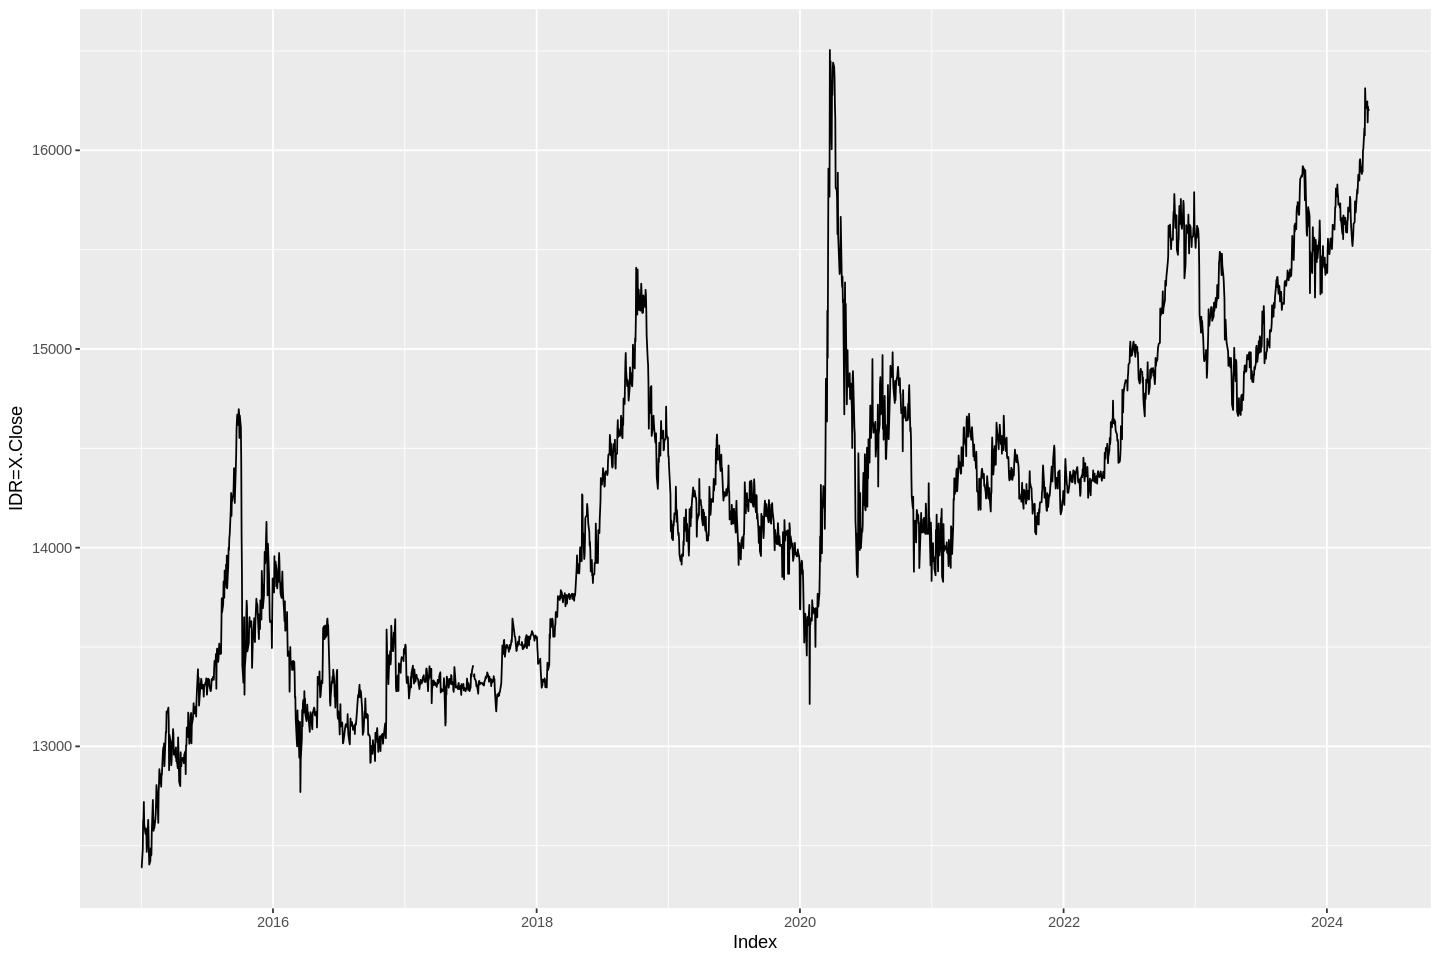

In [ ]:
autoplot(df$`IDR=X.Close`)

Berdasarkan plot runtun waktu data kurs jual dollar terhadap rupiah terlihat bahwa data sangat fluktuatif dan memiliki trend naik. Terlihat juga adanya *volatility clustering* pada data tersebut.

# Peramalan

# Metode Naive

In [ ]:
naive.method <- naive(data,h=5) #peramalan
naive.method

         Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
May 2024          16203 15744.29 16661.71 15501.46 16904.54
Jun 2024          16203 15554.28 16851.72 15210.87 17195.13
Jul 2024          16203 15408.49 16997.51 14987.90 17418.10
Aug 2024          16203 15285.58 17120.42 14799.92 17606.08
Sep 2024          16203 15177.29 17228.71 14634.31 17771.69

,ME,RMSE,MAE,MPE,MAPE,MASE,ACF1
Training set,32.72973,357.9345,239.1115,0.1991706,1.655016,0.4383438,-0.06204329


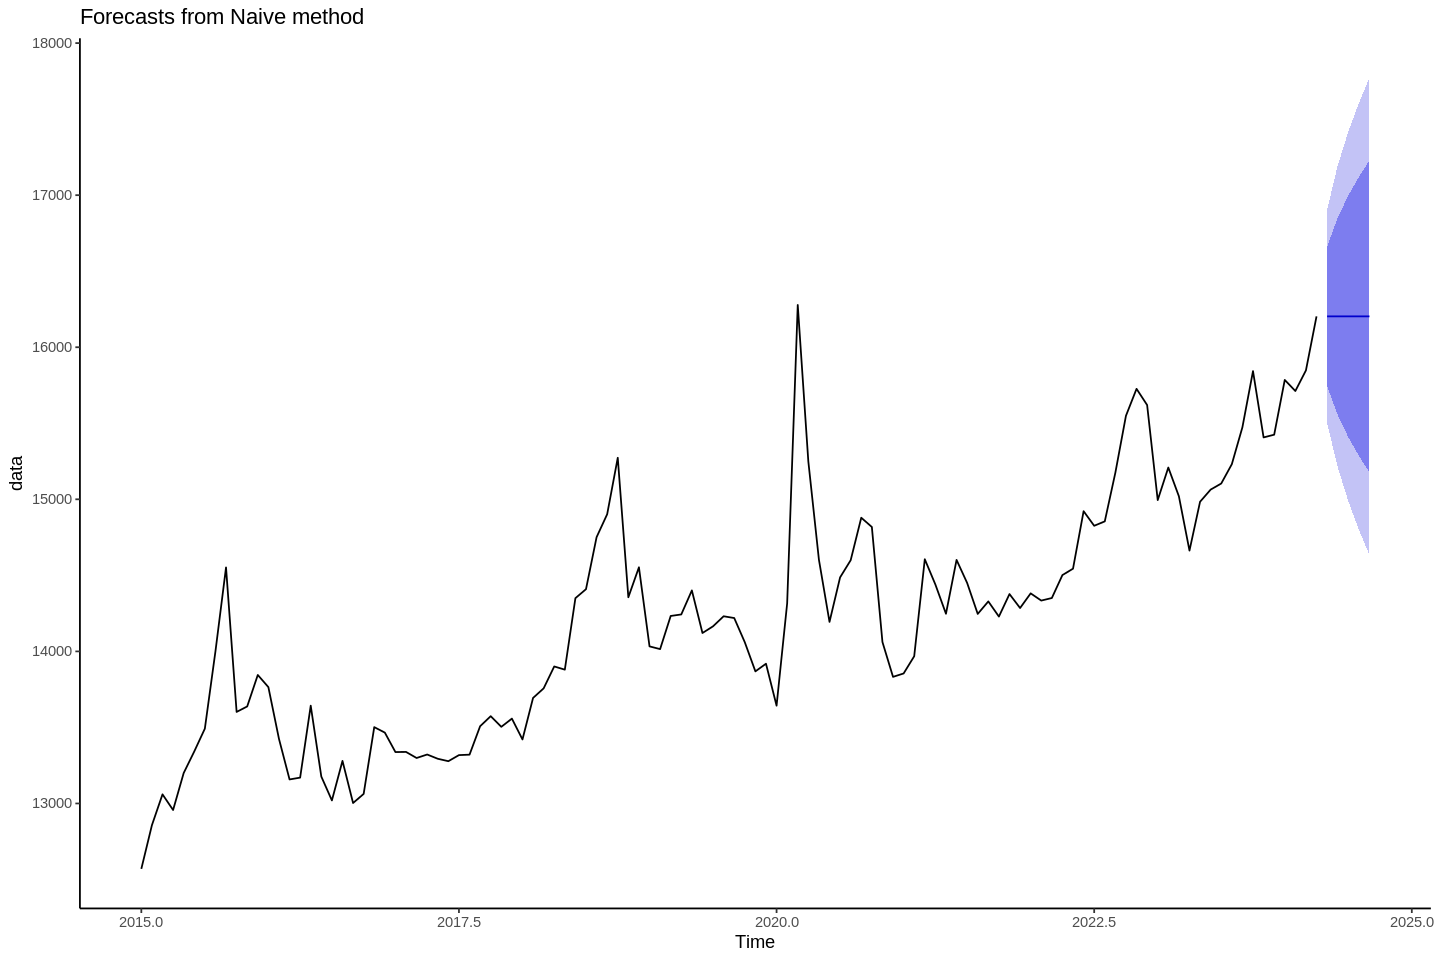

In [ ]:
accuracy(naive.method) #ukuran ketepatan nilai peramalan
autoplot(naive.method) + theme_classic() #plot data ramalan

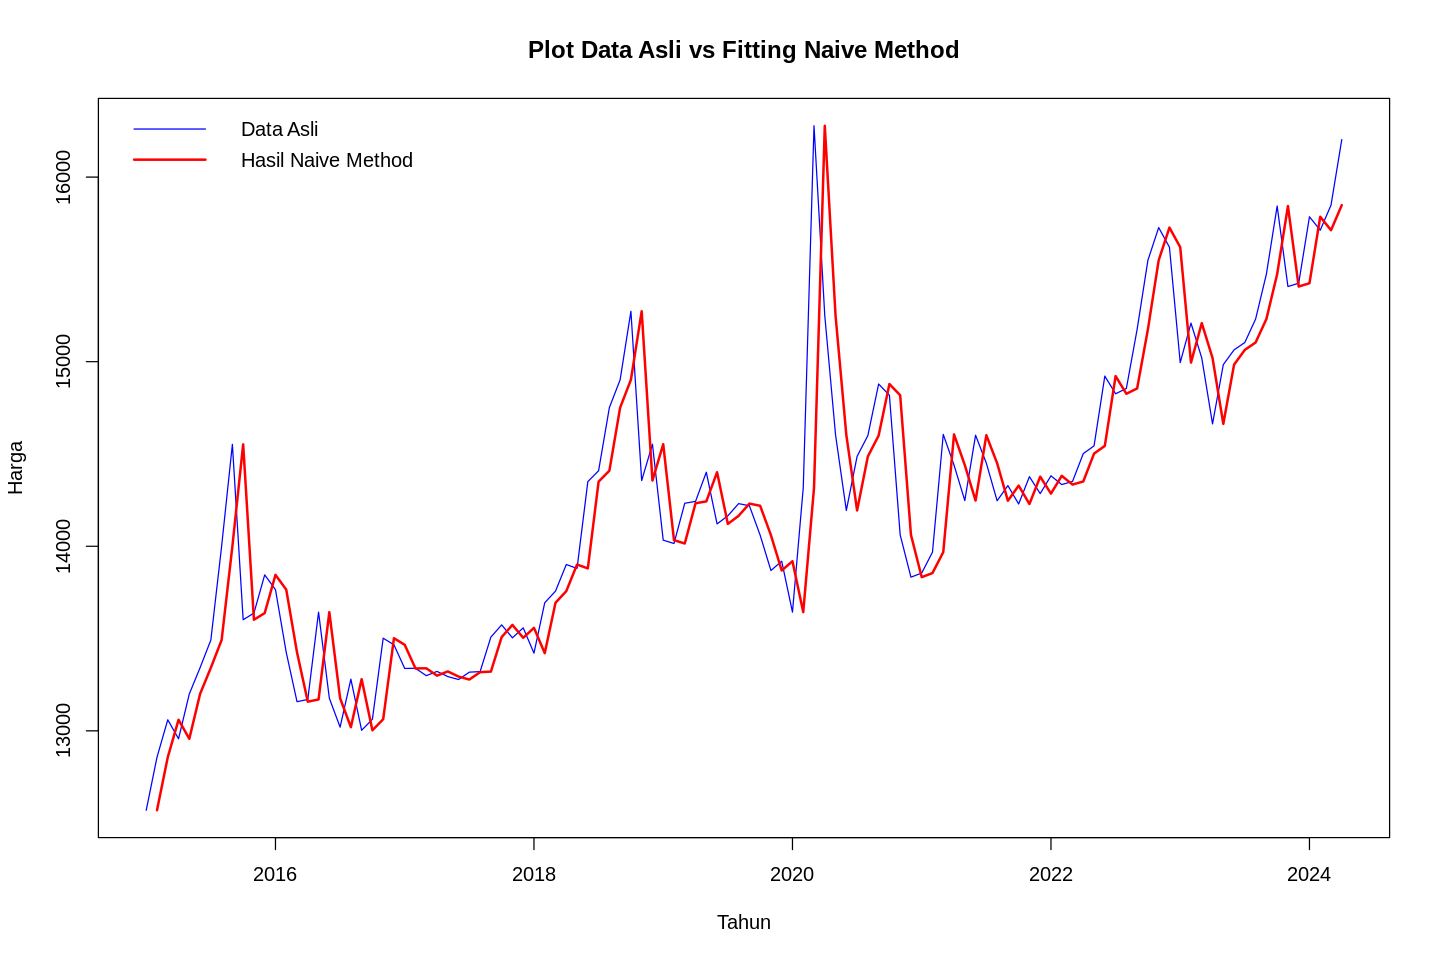

In [ ]:
#plot data asli dan ramalan
plot(naive.method$x,col="blue",lwd=1.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli vs Fitting Naive Method")
lines(naive.method$fitted,col="red",lwd=2.0)
legend("topleft", c("Data Asli", "Hasil Naive Method"), bty="n", lwd=c(1.0,2.0), col=c("blue", "red"))

# Metode Single Moving Average

In [ ]:
# rata-rata bergerak tunggal
k=3 #mendefinisikan nilai k
n=length(data)
MA=array(NA,dim=c(n)) # inisiasi MA
# perulangan untuk forecast rata-rata bergerak tunggal
for(i in 1:n){
  MA[i+k]=mean(data[i:(i+(k-1))])
}
MA=ts(MA, start = c(2015,1), frequency = 12 ) #forecast yg muncul terbatas karena ada NA yang ikut di mean kan
MA
#MSE dan RMSE
e=array(NA,dim=c(n))
for(i in 1:n){
  e[i]=(data[i]-MA[i])^2
}
SSE=sum(e,na.rm=TRUE) #NA.RM=TRUE = NILAI KOSONG DI REMOVE
MSE=mean(e,na.rm=TRUE) # nilai MSE
RMSE=sqrt(MSE) #nilai RMSE
forecast.error <- data.frame('MSE'=MSE, 'RMSE'=RMSE) #membentuk data frame hasil MSE dan RMSE
forecast.error

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2015,NA,NA,NA,12829.00,12958.00,13072.33,13166.33,13344.67,13611.33,14014.67,14051.33,13930.67
2016,13695.00,13749.33,13678.33,13449.33,13251.00,13323.67,13330.00,13280.00,13159.00,13101.00,13115.33,13189.33
2017,13343.67,13435.33,13381.00,13325.33,13320.00,13305.00,13298.00,13296.67,13305.67,13382.33,13467.67,13528.67
2018,13545.33,13494.33,13557.67,13624.00,13784.00,13846.00,14043.67,14213.07,14503.40,14687.40,14975.37,14843.70
2019,14727.37,14314.00,14200.33,14093.67,14163.67,14292.33,14255.00,14229.00,14172.33,14205.13,14170.13,14049.35
2020,13949.22,13810.28,13959.39,14745.71,15280.98,15376.65,14682.02,14427.91,14426.81,14655.12,14765.57,14586.21
2021,14237.40,13916.36,13885.20,14143.02,14337.96,14431.07,14429.60,14433.03,14432.70,14341.70,14268.03,14311.53
2022,14297.07,14347.93,14333.67,14355.60,14395.73,14465.63,14655.93,14763.93,14867.63,14952.07,15193.13,15483.63
2023,15631.90,15447.17,15274.67,15074.67,14964.00,14889.00,14903.67,15050.67,15133.00,15269.67,15516.00,15574.67
2024,15558.33,15539.00,15640.73,15781.73,15921.07,NA,NA,,,,,


MSE,RMSE
<dbl>,<dbl>
168263.7,410.1996


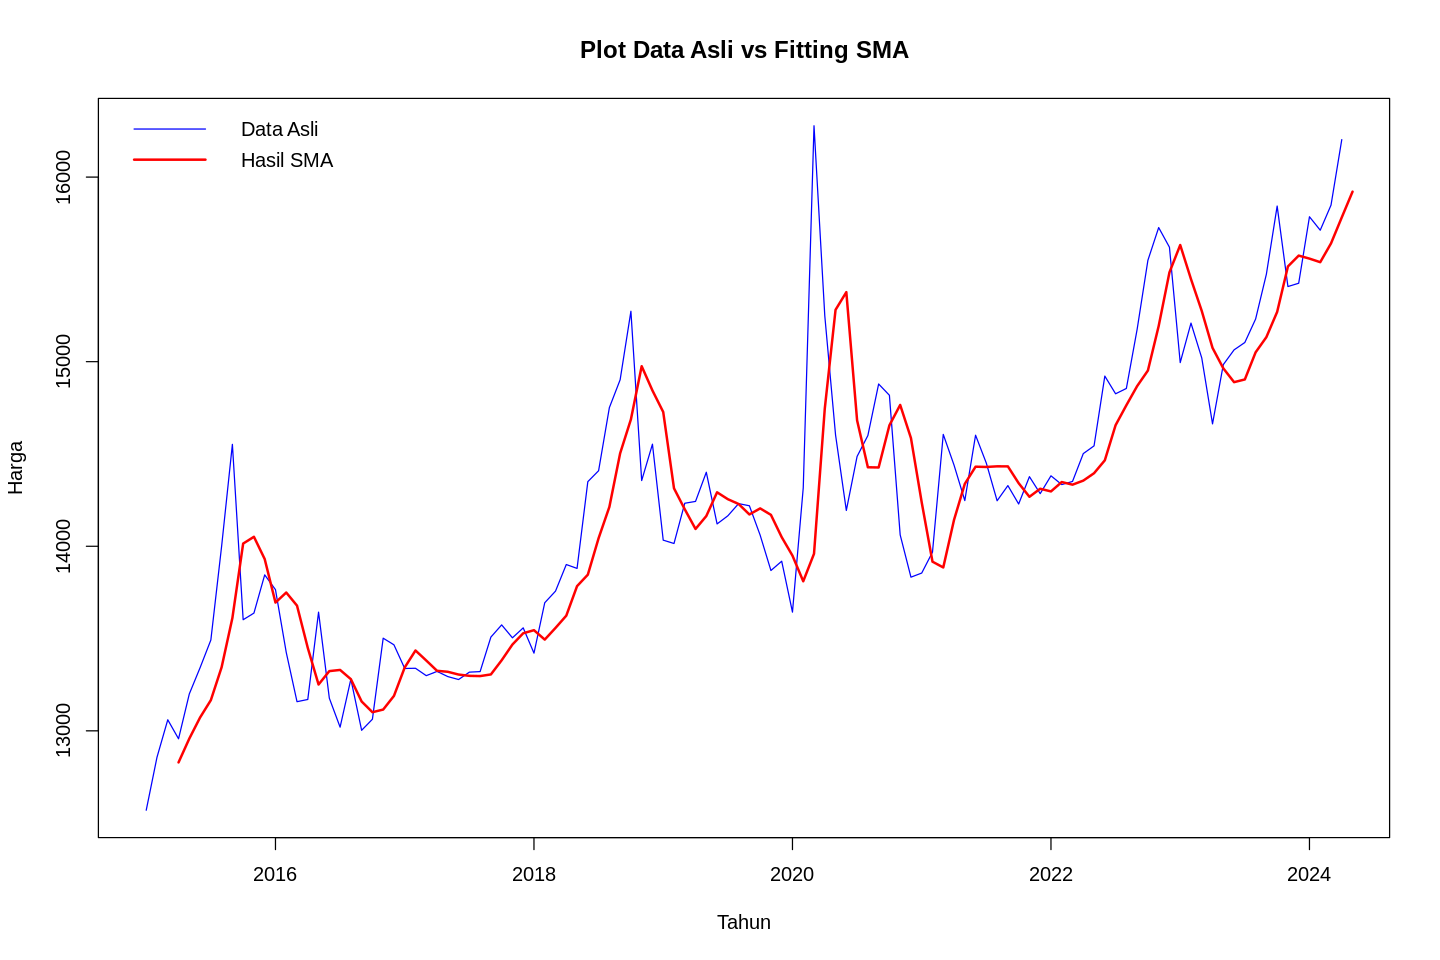

In [ ]:
#plot data asli dan ramalan
plot(data,col="blue",lwd=1.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli vs Fitting SMA")
lines(MA,col="red",lwd=2.0)
legend("topleft", c("Data Asli", "Hasil SMA"), bty="n", lwd=c(1.0,2.0), col=c("blue", "red"))

# Metode Double Moving Average

In [ ]:
k=5 #mendefinisikan nilai k
n=length(data)
MA=array(NA,dim=c(n)) # inisiasi MA

In [ ]:
# perulangan untuk forecast rata-rata bergerak tunggal
for(i in 1:n){
  MA[i+(k-1)]=mean(data[i:(i+(k-1))])
}
#Hitung DMA dengan orde m
m=3 #mendefinisikan nilai m
DMA=array(NA,dim=c(n)) #inisiasi DMA
# perulangan untuk forecast rata-rata bergerak ganda
for(i in 1:n){
  DMA[i+(m-1)+(k-1)]=mean(MA[(i+(k-1)):(i+(m-1)+(k-1))])
}
#Hitung koefisien at
at=array(NA,dim=c(n))
for(i in 1:n){
  at[i+(m-1)+(k-1)]=2*MA[i+(m-1)+(k-1)]-DMA[i+(m-1)+(k-1)]
}
#Hitung koefisien bt
bt=array(NA,dim=c(n))
for(i in 1:n){
  bt[i+(m-1)+(k-1)]=(2/(k-1))*(MA[i+(m-1)+(k-1)]-DMA[i+(m-1)+(k-1)])
}
# nilai prediksi
Prediksi=array(NA,dim=c(n))
for(i in 1:n){
  Prediksi[i+(m-1)+(k-1)+2]=at[i+(m-1)+(k-1)]+bt[i+(m-1)+(k-1)]*2
}
# nilai error
e=array(NA,dim=c(n))
for(i in 1:n){
  e[i]=(data[i+(m-1)+(k-1)+2]-Prediksi[i+(m-1)+(k-1)+2])^2
}
MSE.dma=mean(e,na.rm=TRUE) #nilai MSE, na.rm=TRUE -> missing value dihilangkan
RMSE.dma = sqrt(MSE.dma) #nilai RMSE
forecast.error.dma <- data.frame('MSE'=MSE.dma, 'RMSE'=RMSE.dma) #membentuk data frame hasil MSE dan RMSE
forecast.error.dma

MSE,RMSE
<dbl>,<dbl>
252392.8,502.3871


In [ ]:
# melakukan peramalan
forecast.ts=function(h,N){
  at[n-h]+bt[n-h]*N
}
# ramalan 5 (t=5) periode kedepan
t=5
ramalan=ts(forecast.ts(t-1:t,t))
ramalan

A Time Series:
[1] 15705.83 15920.23 15874.87 15693.35 16167.27

In [ ]:
# data time series
Prediksi=ts(Prediksi, start=c(2015,1), freq=12)
Ramalan=ts(ramalan, start=c(2024,5), freq=12)
Ramalan

,May,Jun,Jul,Aug,Sep
2024,15705.83,15920.23,15874.87,15693.35,16167.27


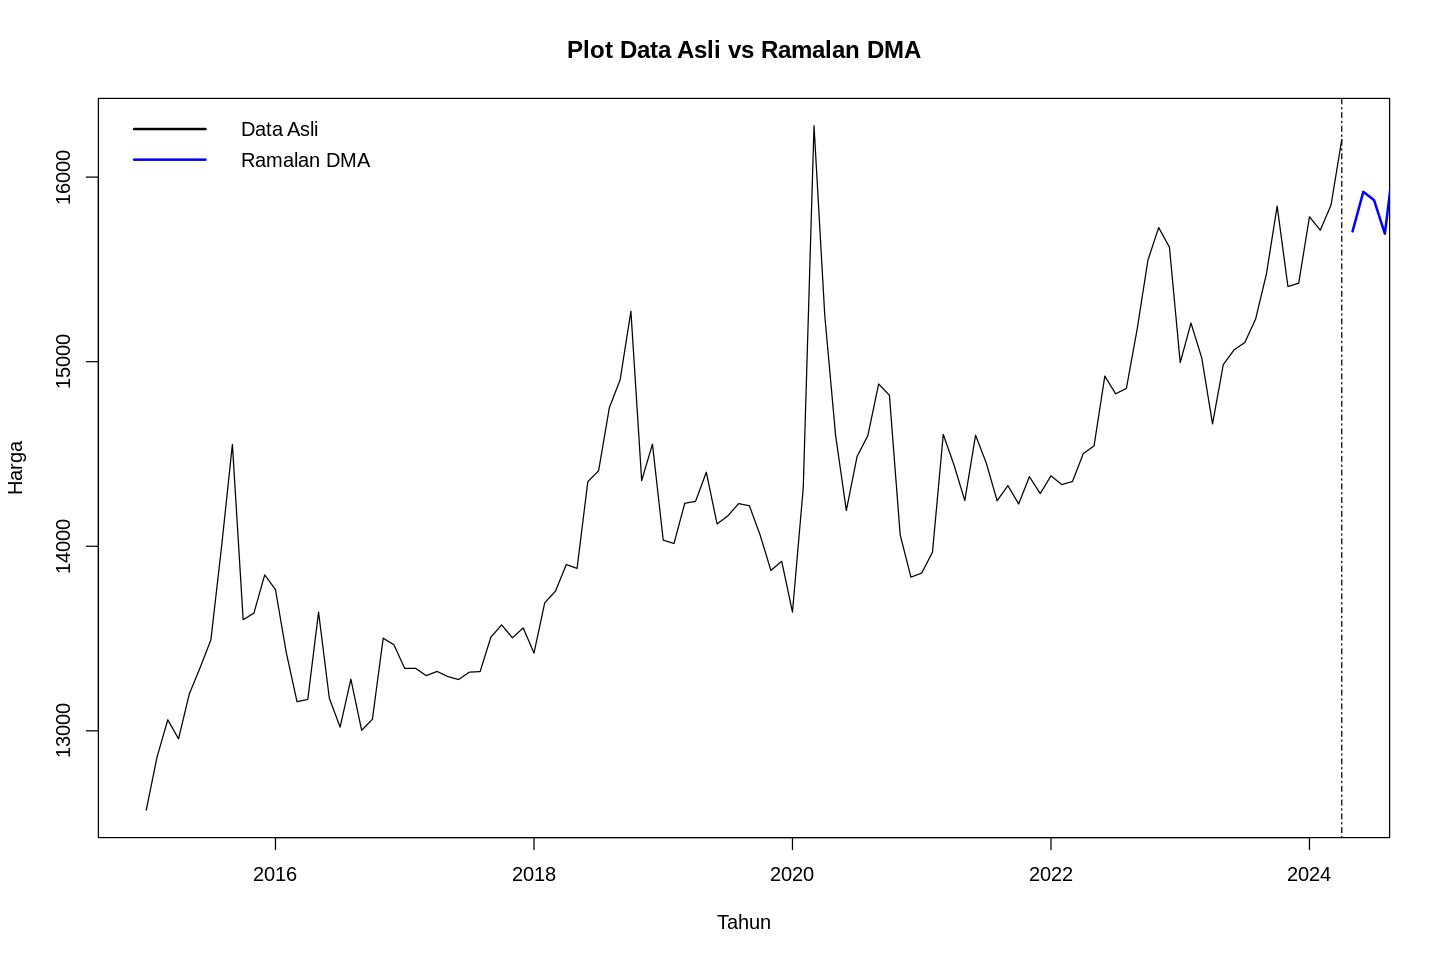

In [ ]:
# plot ramalan
plot(data,col="black",lwd=1.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli vs Ramalan DMA")
limitDate=end(data)[1]+(end(data)[2]-1)/frequency(data)
abline(v=limitDate ,lty=4)
lines(Ramalan,col="blue", lwd=2)
legend("topleft", c("Data Asli", "Ramalan DMA"), bty="n", lwd=2, col=c("black", "blue"))

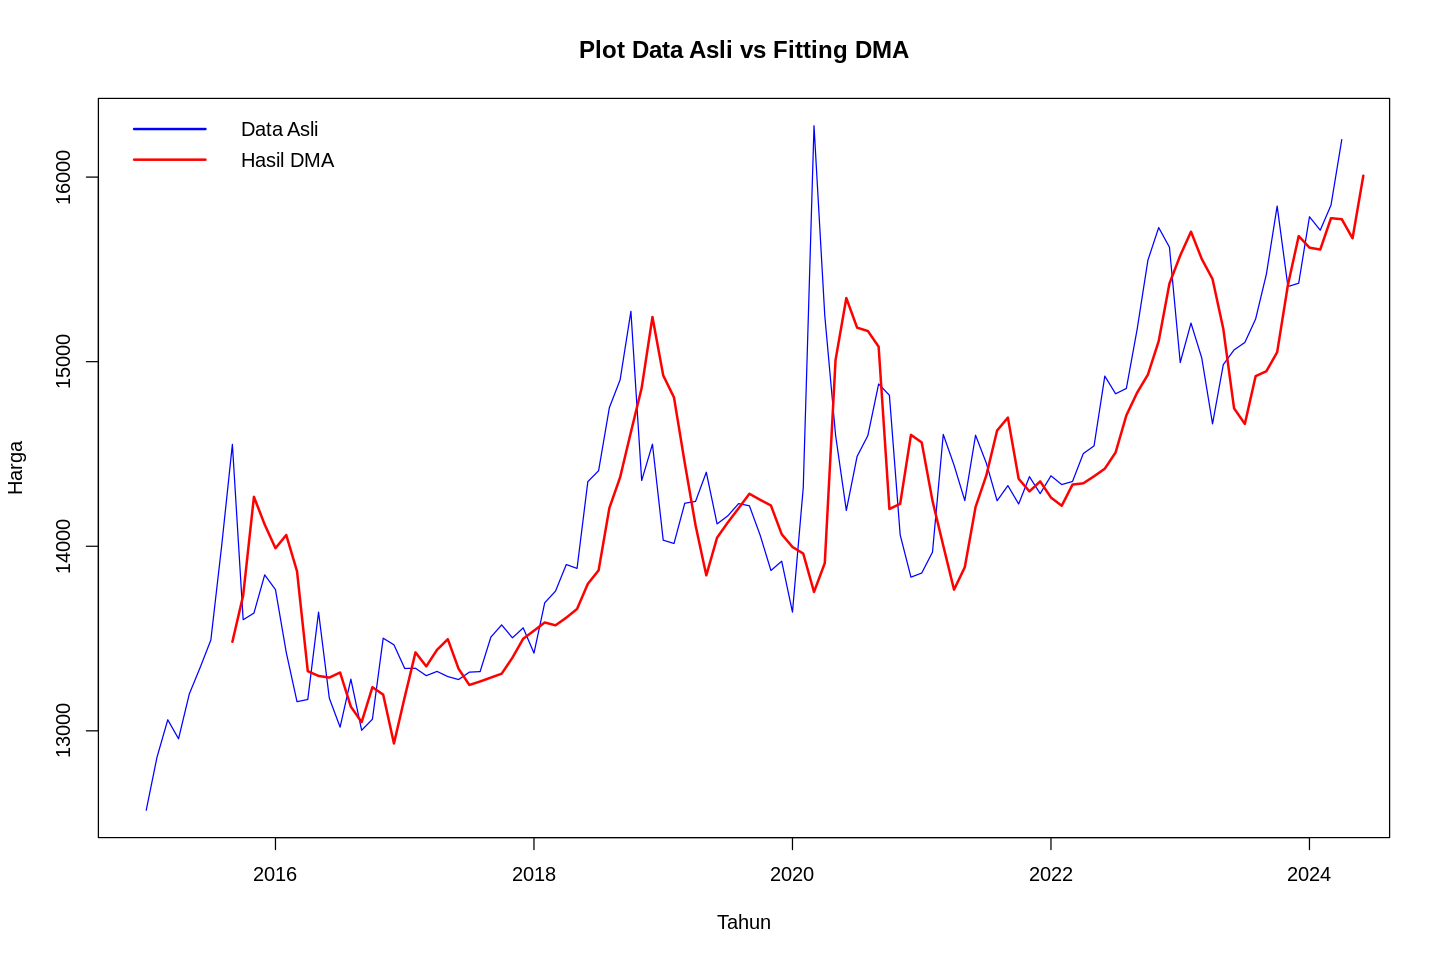

In [ ]:
# plot fitting
plot(data,col="blue",lwd=1.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli vs Fitting DMA")
lines(Prediksi, col="red", lwd=2)
legend("topleft", c("Data Asli", "Hasil DMA"), bty="n", lwd=2, col=c("blue", "red"))

# Simple Exponential Smoothing

,nilaiAlpha,RMSE
,<dbl>,<dbl>
1,0.01,782.9434
2,0.02,717.6592
3,0.03,653.1151
4,0.04,602.7624
5,0.05,565.7884
6,0.06,538.5125


,nilaiAlpha,RMSE
,<dbl>,<dbl>
89,0.89,355.3265


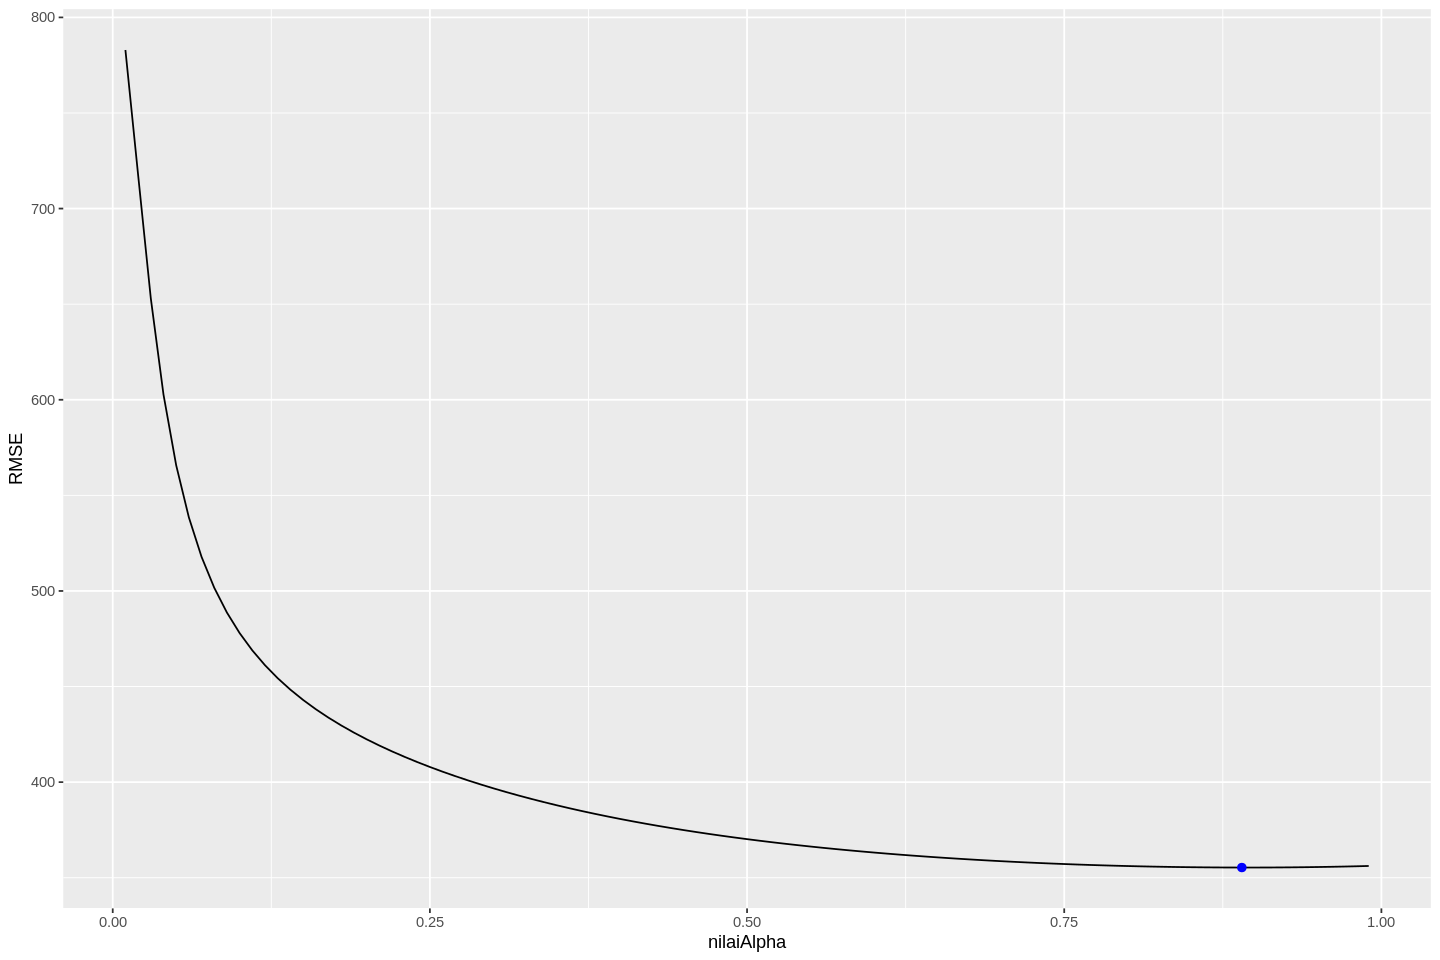

In [ ]:
#Mencari alpha yang meminimumkan RMSE
nilaiAlpha = seq(0.01,0.99, by = 0.01)
RMSE = NA
for (i in seq_along(nilaiAlpha)){
  SES <- ses(data, alpha = nilaiAlpha[i], h = 3)
  RMSE[i] = accuracy(SES)[,2]
}
#Membuat hasil RMSE ke tabel
Tabel.RMSE = data.frame(nilaiAlpha,RMSE)
head(Tabel.RMSE)
#Menentukan alpha yang meminimumkan RMSE
Min.RMSE = Tabel.RMSE[which.min(Tabel.RMSE$RMSE),]
Min.RMSE
#Plot alpha terbaik
ggplot(Tabel.RMSE, aes(nilaiAlpha, RMSE)) +
  geom_line() +
  geom_point(data = Min.RMSE, aes(nilaiAlpha, RMSE), size = 2, color = "blue")

         Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
May 2024       16162.35 15702.86 16621.84 15459.62 16865.08
Jun 2024       16162.35 15547.23 16777.47 15221.61 17103.09
Jul 2024       16162.35 15423.70 16901.00 15032.68 17292.02
Aug 2024       16162.35 15318.05 17006.65 14871.11 17453.60
Sep 2024       16162.35 15224.23 17100.48 14727.61 17597.09

,ME,RMSE,MAE,MPE,MAPE,MASE,ACF1
Training set,35.70086,355.3265,235.5058,0.2171211,1.630452,0.4317337,0.01917285


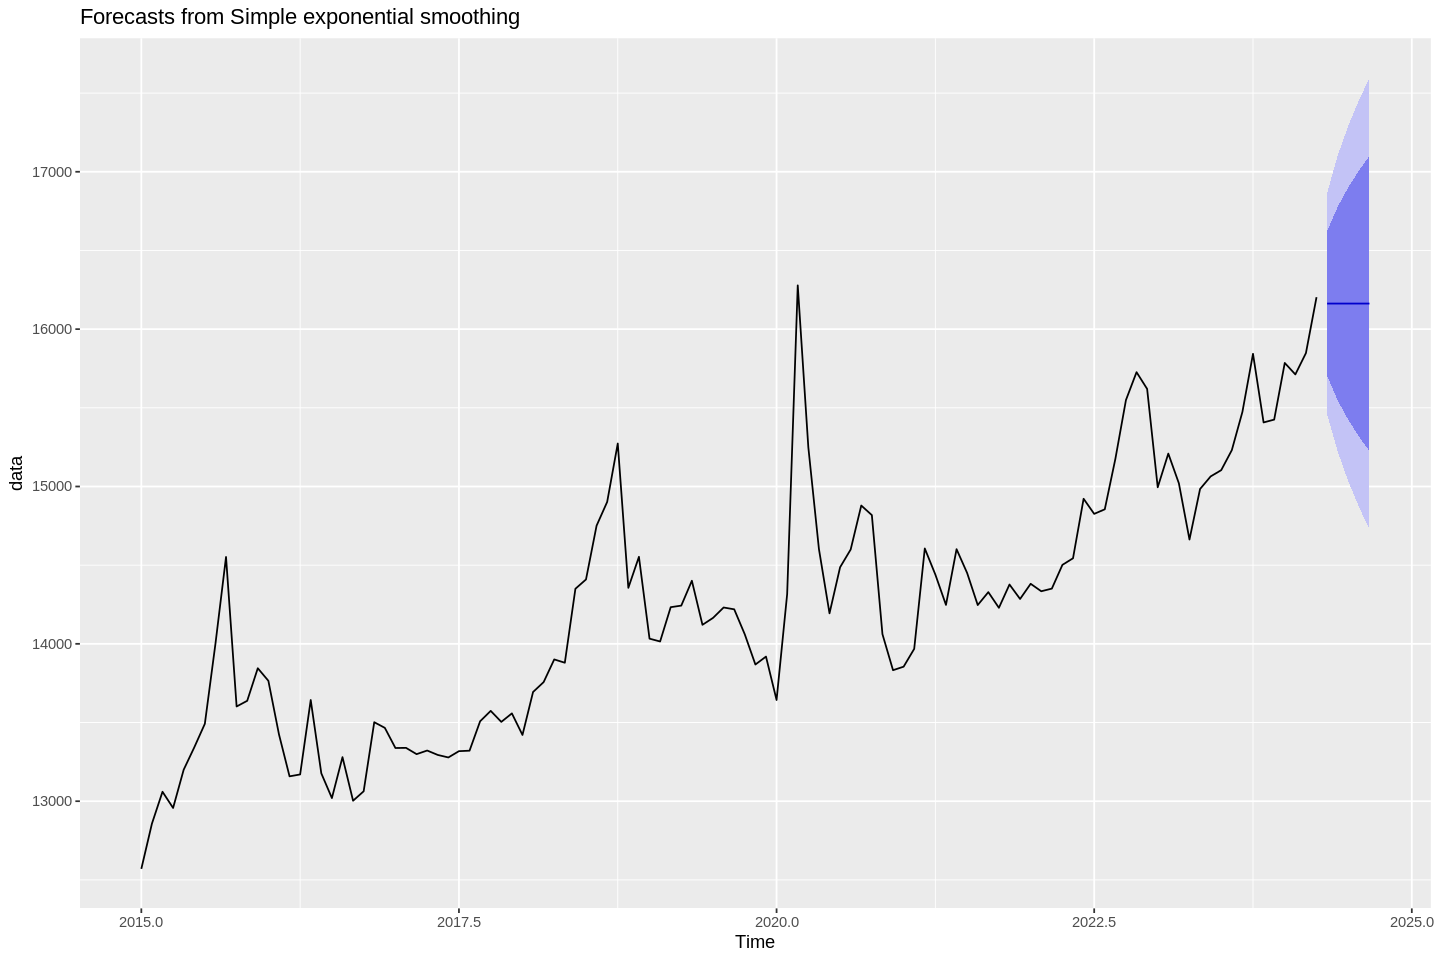

In [ ]:
 #Melakukan Single Exponential Smoothing dengan alpha terbaik
SESOptimum <- ses(data, alpha = 0.89, h = 5)
SESOptimum
accuracy(SESOptimum)
autoplot(SESOptimum)

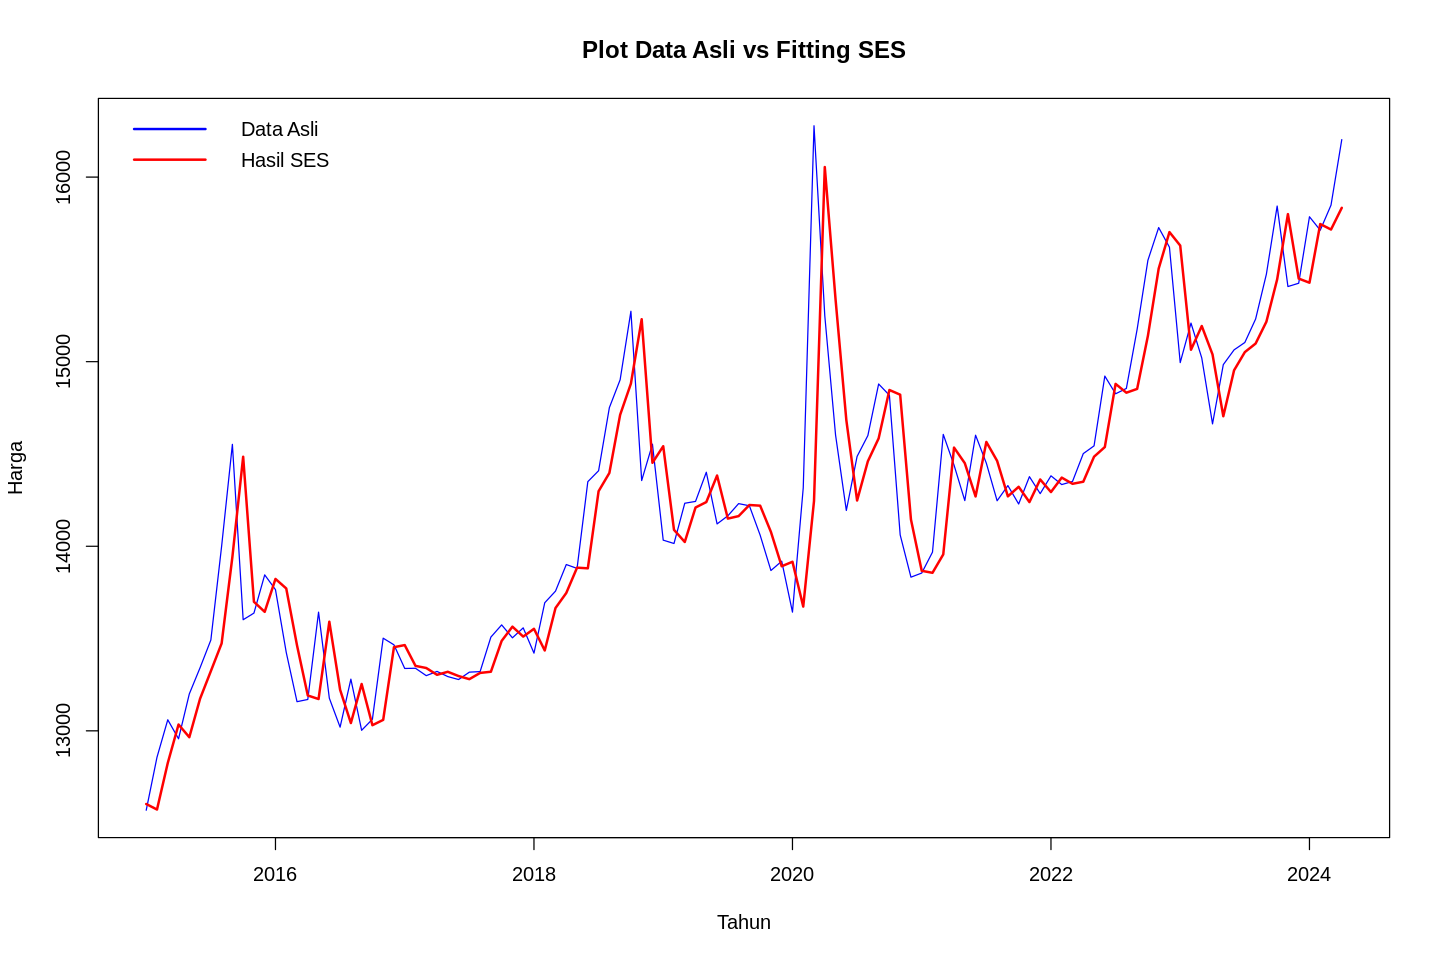

In [ ]:
# plot fitting
plot(data,col="blue",lwd=1.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli vs Fitting SES")
lines(SESOptimum$fitted, col="red", lwd=2)
legend("topleft", c("Data Asli", "Hasil SES"), bty="n", lwd=2, col=c("blue", "red"))

# Double Exponential Smoothing (2 Paramater Holt)

In [ ]:
# membuat fungsi manual untuk peramalan 2 parameter holt dgn argumen y=data, Alpha, Gamma, dan start
holt_manual = function(y, Alpha, Gamma, start = y[1]){
  st_par = y
  st_par[1] = y[1] #inisiasi untuk s1
  bt_par = y
  bt_par[1] =  y[2] - y[1] #inisiasi untuk b1
  n = length(y)+1 #Panjang data forecast lebih satu dari data asli
  forecast = array(NA, dim=c(n)) #Vektor kosong
  n_2 = length(y) #Panjang data error, st, dan bt sama dengan panjang data asli
  error = array(NA, dim=c(n_2)) #Vektor kosong
  for (i in 2:length(y)){ #Menggunakan fungsi perulangan untuk st dengan rumus yang sama pada modul dengan t dimulai dari 2 sampai dengan nilai panjang data asli
    st_par[i] = Alpha*y[i] + (1-Alpha)*(st_par[i-1]+bt_par[i-1])
    for (i in 2:length(y)){ #Menggunakan fungsi perulangan untuk bt dengan rumus yang sama pada modul dengan t dimulai dari 2 sampai dengan nilai panjang data asli
      bt_par[i] = Gamma*(st_par[i]-st_par[i-1]) + (1-Gamma)*bt_par[i-1]
    }
  }
  for (i in 3:n){ #Menggunakan fungsi perulangan untuk forecasting dengan t dimulai dari 3 sampai n yaitu panjang data asli plus 1
    forecast[i] = bt_par[i-1] + st_par[i-1]
  }
  for (i in 3:n_2){ #Menggunakan fungsi perulangan untuk menghitung error^2 dengan t dimulai dari 3 sampai dengan nilai panjang data asli
    error[i] = (y[i] - forecast[i])^2
  }
  max_ln = max(c(length(y), length(st_par), length(forecast), length(bt_par), length(error))) #Mencari variabel dengan panjang data terpanjang
  df = data.frame(Data = c(y,rep(NA, max_ln - length(y))), #Menambahkan baris dengan nilai NA untuk menyamakan panjang data dengan panjang data terpanjang
                  St = c(st_par,rep(NA, max_ln - length(st_par))), # menghitung St sesuai formula yang ada
                  Bt = c(bt_par,rep(NA, max_ln - length(bt_par))), # menghitung Bt sesuai formula yang ada
                  Forecast = c(forecast,rep(NA, max_ln - length(forecast))), # menghitung nilai prediksi/peramalan
                  Error = c(error,rep(NA, max_ln - length(error)))) # menghitung nilai error
  df #Menampilkan hasil ramalan
}
Alpha = rep(seq(0.1,0.9, by = 0.1), times = 9) #Membuat vektor nilai alpha
Gamma = rep(seq(0.1,0.9, by = 0.1), each = 9) #Membuat vektor nilai gamma
RMSE = NA #Vektor kosong
for (i in seq_along(Alpha)){ #Fungsi perulangan untuk mencari RMSE dari kombinasi nilai alpha dan gamma
  for (i in seq_along(Gamma)){
    param = holt_manual(data, Alpha[i], Gamma[i])
    RMSE[i] = sqrt(mean(param$Error,na.rm=TRUE))
  }
}
Tabel.RMSE.Holt = data.frame(Alpha, Gamma, RMSE) #Membuat data frame yang memuat Alpha, Gamma, dan RMSE yg bersesuaian
Tabel.RMSE.Holt
Min.RMSE = Tabel.RMSE.Holt[which.min(Tabel.RMSE.Holt$RMSE),] #Mencari kombinasi nilai alpha dan gamma dengan RMSE terkecil
Min.RMSE


Alpha,Gamma,RMSE
<dbl>,<dbl>,<dbl>
0.1,0.1,781.0717
0.2,0.1,526.9195
0.3,0.1,450.4615
0.4,0.1,416.2727
0.5,0.1,397.8697
0.6,0.1,387.0204
0.7,0.1,380.4327
0.8,0.1,376.7372
0.9,0.1,375.4497


,Alpha,Gamma,RMSE
,<dbl>,<dbl>,<dbl>
9,0.9,0.1,375.4497


In [ ]:
best.holt = holt_manual(data, 0.9, 0.1) #Kombinasi alpha dan gamma dengan RMSE terkecil
RMSE.best.holt = sqrt(mean(best.holt$Error,na.rm=TRUE))
# fungsi untuk menampilkan hasil forecast beserta Alpha, Gamma, dan RMSE paling optimal
result.holt = function(best.holt, RMSE.best.holt, Alpha, Gamma){
  print(best.holt)
  cat("\n", "-----------------\n", "RMSE = ", RMSE.best.holt,
      "\n", "Alpha = ", Alpha,
      "\n", "Gamma = ", Gamma)
}
result.holt(best.holt, RMSE.best.holt, 0.9, 0.1) #Hasil

        Data       St           Bt Forecast        Error
1   12570.00 12570.00 287.00000000       NA           NA
2   12857.00 12857.00 287.00000000       NA           NA
3   13060.00 13068.40 279.44000000 13144.00 7.056000e+03
4   12957.00 12996.08 244.26440000 13347.84 1.527559e+05
5   13200.00 13204.03 240.63304400 13240.35 1.627993e+03
6   13342.00 13352.27 231.39293444 13444.67 1.054069e+04
7   13492.00 13501.17 223.14355938 13583.66 8.401505e+03
8   14000.00 13972.43 247.95570153 13724.31 7.600523e+04
9   14552.00 14518.84 277.80090261 14220.39 1.099674e+05
10  13602.00 13721.46 170.28334148 14796.64 1.427164e+06
11  13638.00 13663.37 147.44608464 13891.75 6.438769e+04
12  13845.00 13841.58 150.52221134 13810.82 1.168217e+03
13  13765.00 13787.71 130.08282499 13992.10 5.157636e+04
14  13425.00 13474.28  85.73143210 13917.79 2.428452e+05
15  13158.00 13198.20  49.55046392 13560.01 1.616126e+05
16  13170.00 13177.78  42.55282535 13247.75 6.045302e+03
17  13643.00 13600.73  80.59330

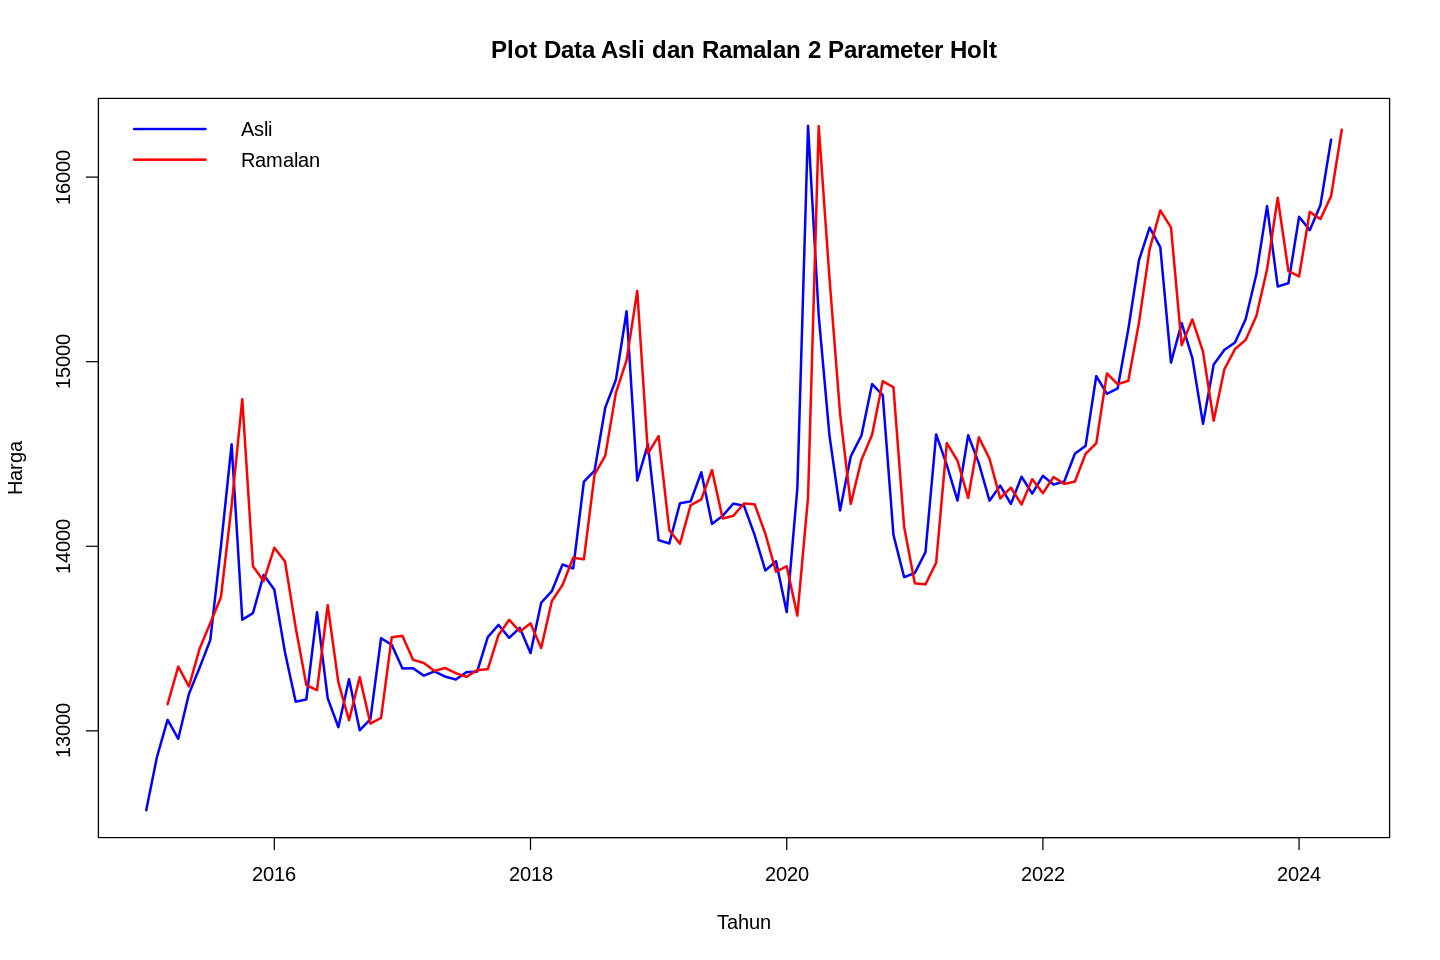

In [ ]:
##### Data Time Series #####
data.plot = ts(best.holt$Data, start=c(2015, 1), freq=12) #Membuat data menjadi bentuk timeseries
forecast.holt = ts(best.holt$Forecast, start=c(2015, 1), freq=12)
##### Plot Data #####
plot(data.plot, type="l", col="blue", lwd=2, xlab="Tahun", ylab="Harga", main="Plot Data Asli dan Ramalan 2 Parameter Holt")
lines(forecast.holt, col="red", lwd=2)
legend("topleft", c("Asli", "Ramalan"), bty="n", lwd=2, col=c("blue", "red"))

# Metode Triple Exponential Smoothing (Winter Multiplicative)

Holt-Winters exponential smoothing with trend and multiplicative seasonal component.

Call:
HoltWinters(x = data, seasonal = c("multiplicative"))

Smoothing parameters:
 alpha: 0.7037935
 beta : 0.005775626
 gamma: 1

Coefficients:
            [,1]
a   1.597391e+04
b   1.538170e-01
s1  9.994294e-01
s2  9.979193e-01
s3  9.930514e-01
s4  9.978266e-01
s5  1.017746e+00
s6  1.032661e+00
s7  1.012247e+00
s8  1.005878e+00
s9  1.000162e+00
s10 1.001978e+00
s11 1.016532e+00
s12 1.014341e+00

         Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
May 2024       15964.95 15433.94 16495.96 15152.84 16777.06
Jun 2024       15940.98 15290.72 16591.24 14946.50 16935.46
Jul 2024       15863.37 15113.05 16613.69 14715.86 17010.89
Aug 2024       15939.81 15096.24 16783.37 14649.69 17229.92
Sep 2024       16258.16 15319.53 17196.79 14822.65 17693.67

,ME,RMSE,MAE,MPE,MAPE,MASE,ACF1
Training set,48.12021,415.0726,293.7089,0.2995831,2.036091,0.5384327,0.1274176


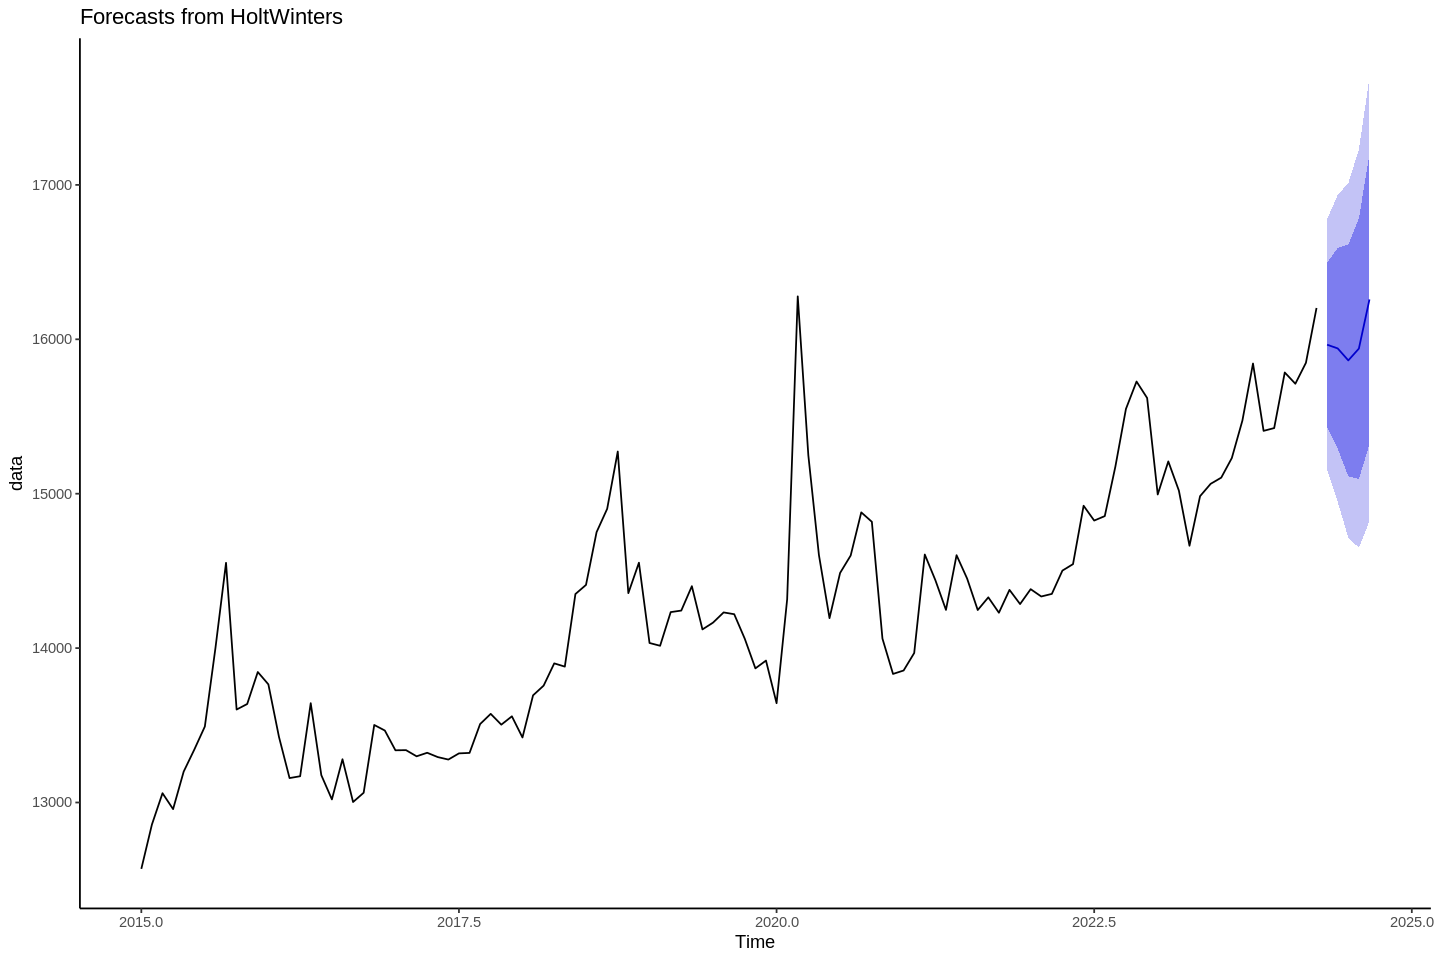

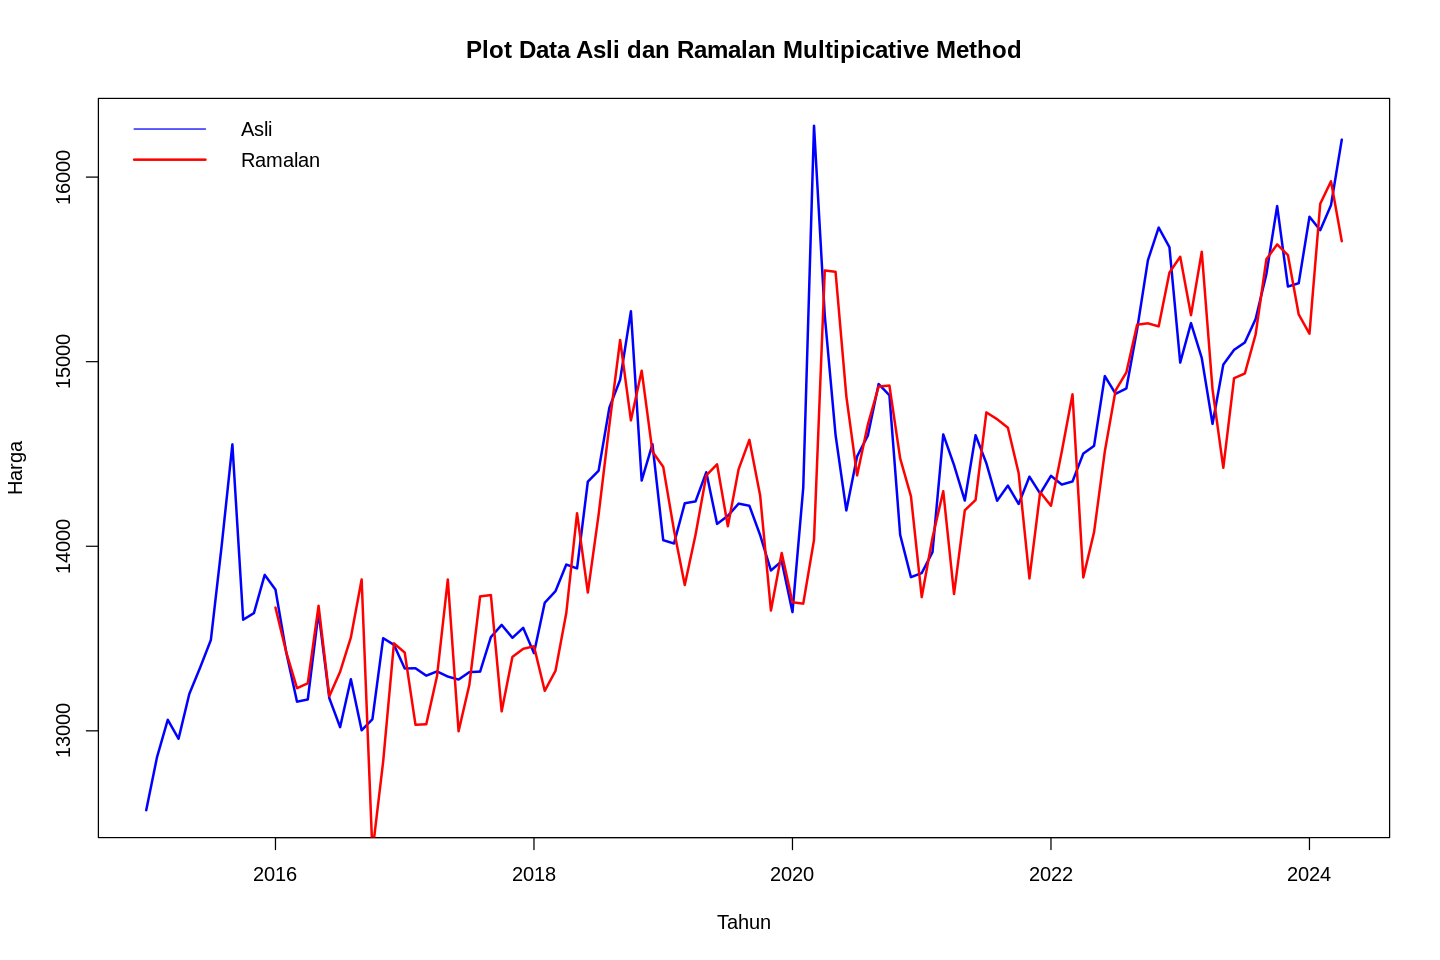

In [ ]:
# winter multiplikatif dengan langsung ke alpha beta gamma terbaik
Multiplikatif<- HoltWinters(data,seasonal = c("multiplicative"))
Multiplikatif
# memprediksi data untuk 5 periode ke depan
Multiplikatif.pred <- forecast(Multiplikatif,h=5)
Multiplikatif.pred
# menghitung akurasi (forecast error)
accuracy(Multiplikatif.pred)
#membuat plot hasil peramalan
autoplot(Multiplikatif.pred) + theme_classic()
plot(Multiplikatif.pred$x,col="blue",lwd=2.0, xlab="Tahun", ylab="Harga", main="Plot Data Asli dan Ramalan Multipicative Method")
lines(Multiplikatif.pred$fitted,col="red",lwd=2.0)
legend("topleft", c("Asli", "Ramalan"), bty="n", lwd=c(1.0,2.0), col=c("blue", "red"))

# Klasifikasi Pegels

In [ ]:
##### Membuat Fungsi Klasifikasi Pegels dengan Tren dan Musiman Multiplikatif#####
##### Panjang Musiman ######
L = 12
pegels_tren_multiplicative = function(data, L, alpha, theta, beta) { #L adalah panjang musiman
  s_t = NA #Vektor kosong
  d_t = NA
  a_t = NA
  p = NA
  q = NA
  f_t = NA
  error = NA
  m = 1 #Peramalan untuk 1 periode ke depan
  s_t[L] = mean(data[1:L]) #Inisiasi s_t pada saat periode ke- L (panjang musiman)
  d_t[1:L] = data[1:L]/s_t[L] # Inisiasi d_t dari periode 1 sampai dengan periode ke- L
  a_t[L] = (1/L^2)*(sum(data[(L+1):(L+L)])-sum(data[1:L])) #Inisiasi a_t pada saar periode ke- L
  p[L+1] = data[L+1]/d_t[L+1-L] #Inisiasi p pada periode ke- L+1
  q[L+1] = s_t[L]+a_t[L] #Inisiasi q pada periode ke- L+1
  s_t[L+1] = alpha*p[L+1]+(1-alpha)*q[L+1] #Nilai s_t pada periode ke- L+1 dengan menggunakan rumus yang sesuai di modul
  d_t[L+1] = theta*(data[L+1]/s_t[L+1]) + (1-theta)*d_t[L+1-L] # Nilai d_t pada periode ke- L+1 dengan menggunakan rumus yang sesuai di modul
  a_t[L+1] = beta*(s_t[L+1]-s_t[L])+(1-beta)*a_t[L] #Nilai a_t pada periode ke- L+1 dengan menggunakan rumus yang sesuai di modul
  for (i in (L+2):length(data)){ #Perulangan untuk mencari nilai p, q, s_t, d_t, dan a_t pada periode ke- L+2 sampai dengan periode ke- panjang data
    p[i] = data[i]/d_t[i-L]
    q[i] = s_t[i-1]+a_t[i-1]
    s_t[i] = alpha*p[i]+(1-alpha)*q[i]
    d_t[i] = theta*(data[i]/s_t[i]) + (1-theta)*d_t[i-L]
    a_t[i] = beta*(s_t[i]-s_t[i-1])+(1-beta)*a_t[i-1]
  }
  for (i in (L+2):(length(data)+m)){ #Perulangan untuk mencari nilai forecast pada periode ke- L+2 sampai dengan periode ke- panjang data + m
    f_t[i] = (s_t[i-m] + m*a_t[i-m])*d_t[i-L]
  }
  for (i in (L+2):(length(data))) { #Perulangan untuk mencari nilai error^2 pada periode ke- L+2 sampai dengan periode ke- panjang data
    error[i] = (data[i] - f_t[i])^2
  }
  max_ln = max(c(length(data), length(s_t), length(d_t), length(a_t),
                 length(p), length(q), length(f_t), length(error))) #Mencari variabel dengan panjang data terpanjang
  df = data.frame(Data = c(data,rep(NA, max_ln - length(data))), #Menambahkan baris dengan nilai NA untuk menyamakan panjang data dengan panjang data terpanjang
                  St = c(s_t,rep(NA, max_ln - length(s_t))),
                  Dt = c(d_t,rep(NA, max_ln - length(d_t))),
                  At = c(a_t,rep(NA, max_ln - length(a_t))),
                  P = c(p,rep(NA, max_ln - length(p))),
                  Q = c(q,rep(NA, max_ln - length(q))),
                  Forecast = c(f_t,rep(NA, max_ln - length(f_t))),
                  Error_Squared = c(error,rep(NA, max_ln - length(error))))
  df #Menampilkan hasil ramalan
}
##### Menjalankan Fungsi #####
options(max.print = 100000)
#untuk bisa menampilkan seluruh barus
pegels_tren_multiplicative(data, 12, 0.3, 0.2, 0.2)
#Menjalankan fungsi dengan parameter sembarang
##### Mencari Alpha, Theta, dan Beta Optimal ####
Alpha = rep(seq(0.1,0.9, by = 0.1), times = 9) #Membuat vektor nilai alpha
Theta = rep(seq(0.1,0.9, by = 0.1), each = 9) #Membuat vektor nilai theta
Beta = rep(seq(0.1,0.9, by = 0.1), times = 3, each = 3) #Membuat vektor nilai beta
RMSE = NA #Vektor kosong
for (i in seq_along(Alpha)){ #Fungsi perulangan untuk mencari RMSE dari kombinasi nilai alpha, theta, dan beta
  param = pegels_tren_multiplicative(data, 12, Alpha[i], Theta[i], Beta[i])
  RMSE[i] = sqrt(mean(param$Error,na.rm=TRUE))
}
Tabel.RMSE.Pegels = data.frame(Alpha, Theta, Beta, RMSE) #Membuat tabel RMSE
head(Tabel.RMSE.Pegels)
tail(Tabel.RMSE.Pegels)
Min.RMSE = Tabel.RMSE.Pegels[which.min(Tabel.RMSE.Pegels$RMSE),] #Mencari kombinasi nilai alpha, gamma, beta dengan RMSE terkecil
Min.RMSE

Data,St,Dt,At,P,Q,Forecast,Error_Squared
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12570,NA,0.9362257,NA,NA,NA,NA,NA
12857,NA,0.9576017,NA,NA,NA,NA,NA
13060,NA,0.9727213,NA,NA,NA,NA,NA
12957,NA,0.9650498,NA,NA,NA,NA,NA
13200,NA,0.9831487,NA,NA,NA,NA,NA
13342,NA,0.9937250,NA,NA,NA,NA,NA
13492,NA,1.0048971,NA,NA,NA,NA,NA
14000,NA,1.0427335,NA,NA,NA,NA,NA
14552,NA,1.0838469,NA,NA,NA,NA,NA


,Alpha,Theta,Beta,RMSE
,<dbl>,<dbl>,<dbl>,<dbl>
1,0.1,0.1,0.1,600.7061
2,0.2,0.1,0.1,585.8876
3,0.3,0.1,0.1,583.8187
4,0.4,0.1,0.2,615.7493
5,0.5,0.1,0.2,604.1024
6,0.6,0.1,0.2,593.0990


,Alpha,Theta,Beta,RMSE
,<dbl>,<dbl>,<dbl>,<dbl>
76,0.4,0.9,0.8,2222.8770
77,0.5,0.9,0.8,1221.8970
78,0.6,0.9,0.8,875.5808
79,0.7,0.9,0.9,684.2351
80,0.8,0.9,0.9,608.5720
81,0.9,0.9,0.9,644.6055


,Alpha,Theta,Beta,RMSE
,<dbl>,<dbl>,<dbl>,<dbl>
30,0.3,0.4,0.1,515.2677


        Data       St        Dt          At        P        Q Forecast
1   12570.00       NA 0.9362257          NA       NA       NA       NA
2   12857.00       NA 0.9576017          NA       NA       NA       NA
3   13060.00       NA 0.9727213          NA       NA       NA       NA
4   12957.00       NA 0.9650498          NA       NA       NA       NA
5   13200.00       NA 0.9831487          NA       NA       NA       NA
6   13342.00       NA 0.9937250          NA       NA       NA       NA
7   13492.00       NA 1.0048971          NA       NA       NA       NA
8   14000.00       NA 1.0427335          NA       NA       NA       NA
9   14552.00       NA 1.0838469          NA       NA       NA       NA
10  13602.00       NA 1.0130900          NA       NA       NA       NA
11  13638.00       NA 1.0157713          NA       NA       NA       NA
12  13845.00 13426.25 1.0311889 -10.0208333       NA       NA       NA
13  13765.00 13802.16 0.9606586  28.5718412 14702.65 13416.23       NA
14  13

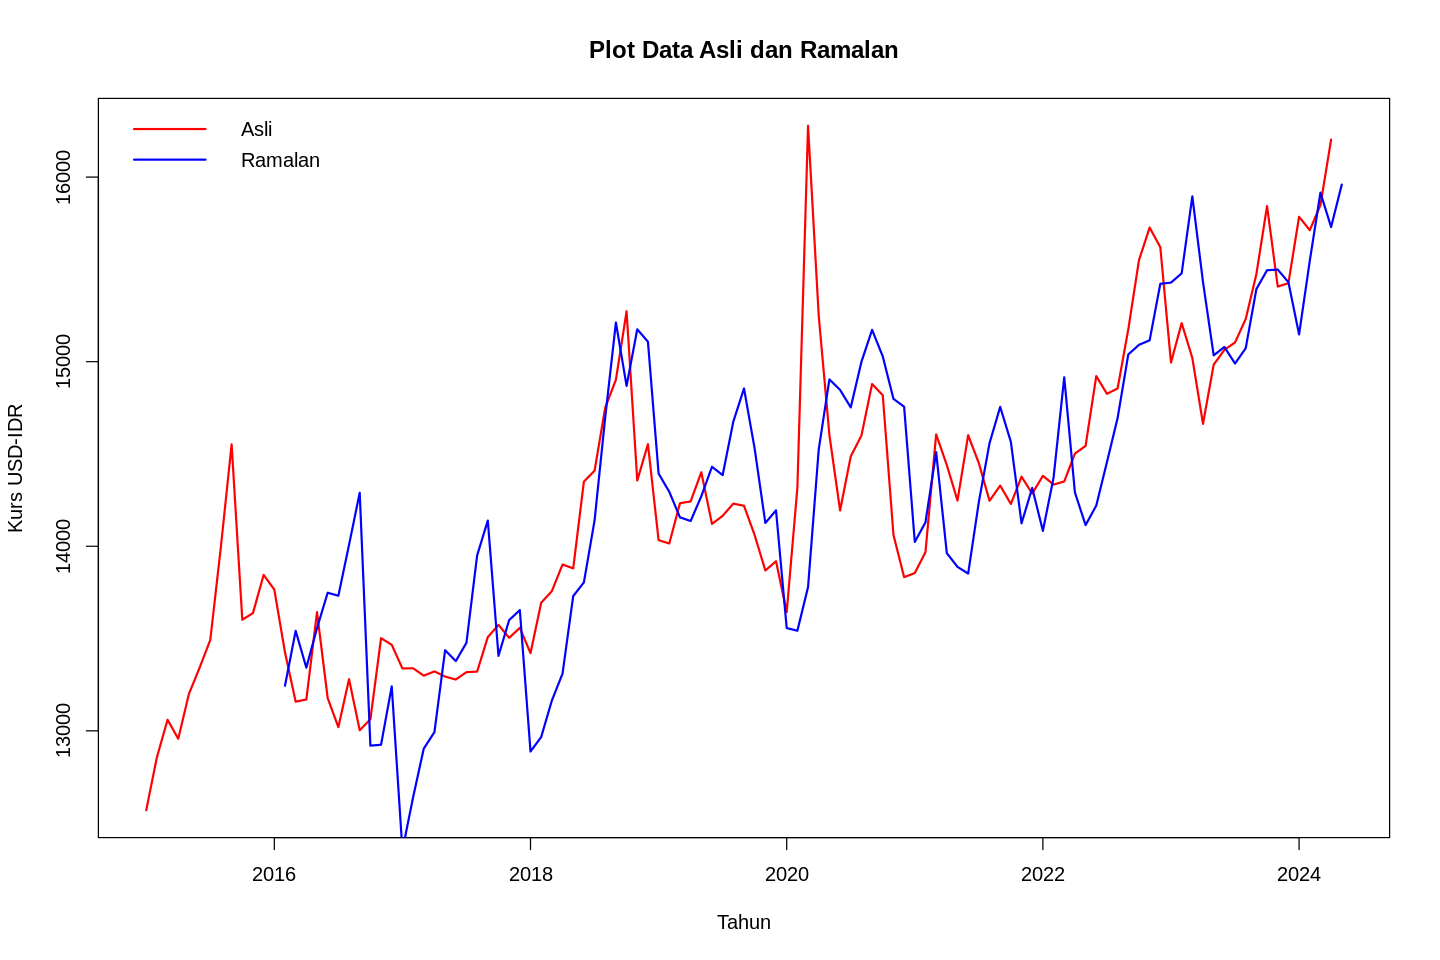

In [ ]:
##### Alpha, Theta, dan, Beta Optimal ####
best = pegels_tren_multiplicative(data, 12, 0.3, 0.4, 0.1)
RMSE.best = sqrt(mean(best$Error_Squared,na.rm=TRUE))
result = function (best, RMSE.best, Alpha, Theta, Beta){
  print(best)
  cat("\n", "-----------------\n", "RMSE = ", RMSE.best,
      "\n", "Alpha = ", Alpha, "\n", "Theta = ", Theta,
      "\n", "Beta = ", Beta)
  return()
}
hasil = result(best, RMSE.best, 0.3, 0.4, 0.1)
##### Data Time Series #####
data.plot = ts(best$Data, start = c(2015,1), freq=12)
forecast.plot = ts(best$Forecast, start = c(2015,1), freq=12)
#### Membuat Plot Data Asli vs Data Ramalan ####
plot(data.plot, type="l", col="red", lwd=1.75, xlab="Tahun", ylab="Kurs USD-IDR", main="Plot Data Asli dan Ramalan")
lines(forecast.plot, col="blue", lwd=1.75)
legend("topleft", c("Asli", "Ramalan"), bty="n", lwd=1.75, col=c("red", "blue"))

# ARIMA

In [ ]:
library(lmtest)

In [ ]:
#Stationarity Test
adf.test(data, k=12)


	Augmented Dickey-Fuller Test

data:  data
Dickey-Fuller = -2.7526, Lag order = 12, p-value = 0.2643
alternative hypothesis: stationary


In [ ]:
#Checking the number of differences required
ndiffs(data,"adf")

Warning message in ndiffs(data, "adf"):
“Specified alpha value is larger than the maximum, setting alpha=0.1”


[1] 1

Warning message in adf.test(ddif1):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  ddif1
Dickey-Fuller = -6.299, Lag order = 4, p-value = 0.01
alternative hypothesis: stationary


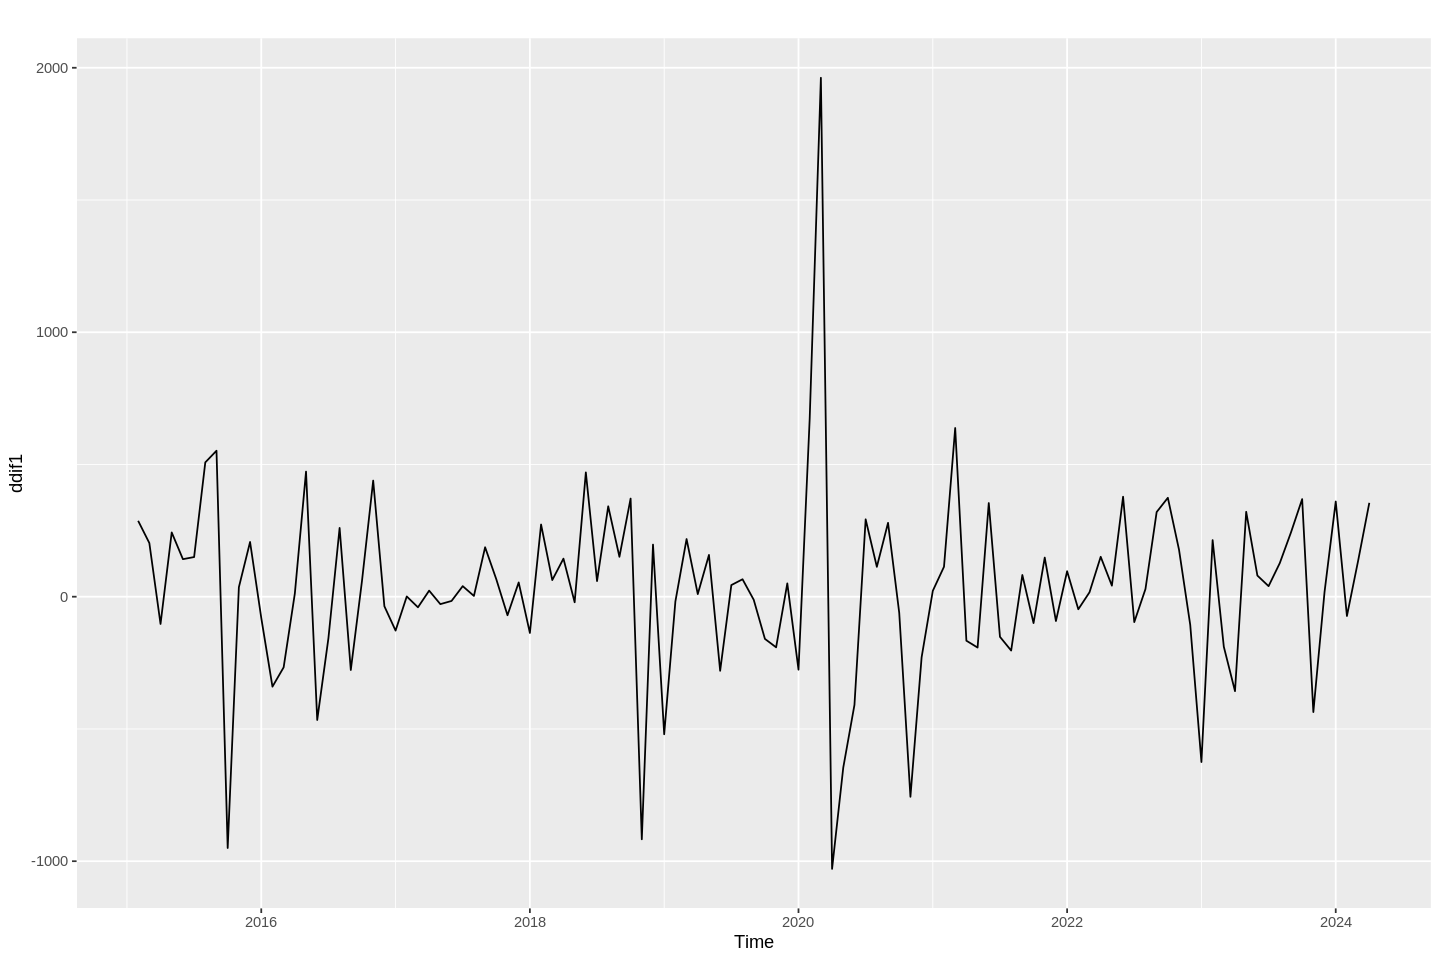

In [ ]:
#Diff 1
ddif1 = diff(data, differences=1)
adf.test(ddif1)
autoplot(ddif1)

Warning message in adf.test(dtrans1):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  dtrans1
Dickey-Fuller = -6.2161, Lag order = 4, p-value = 0.01
alternative hypothesis: stationary


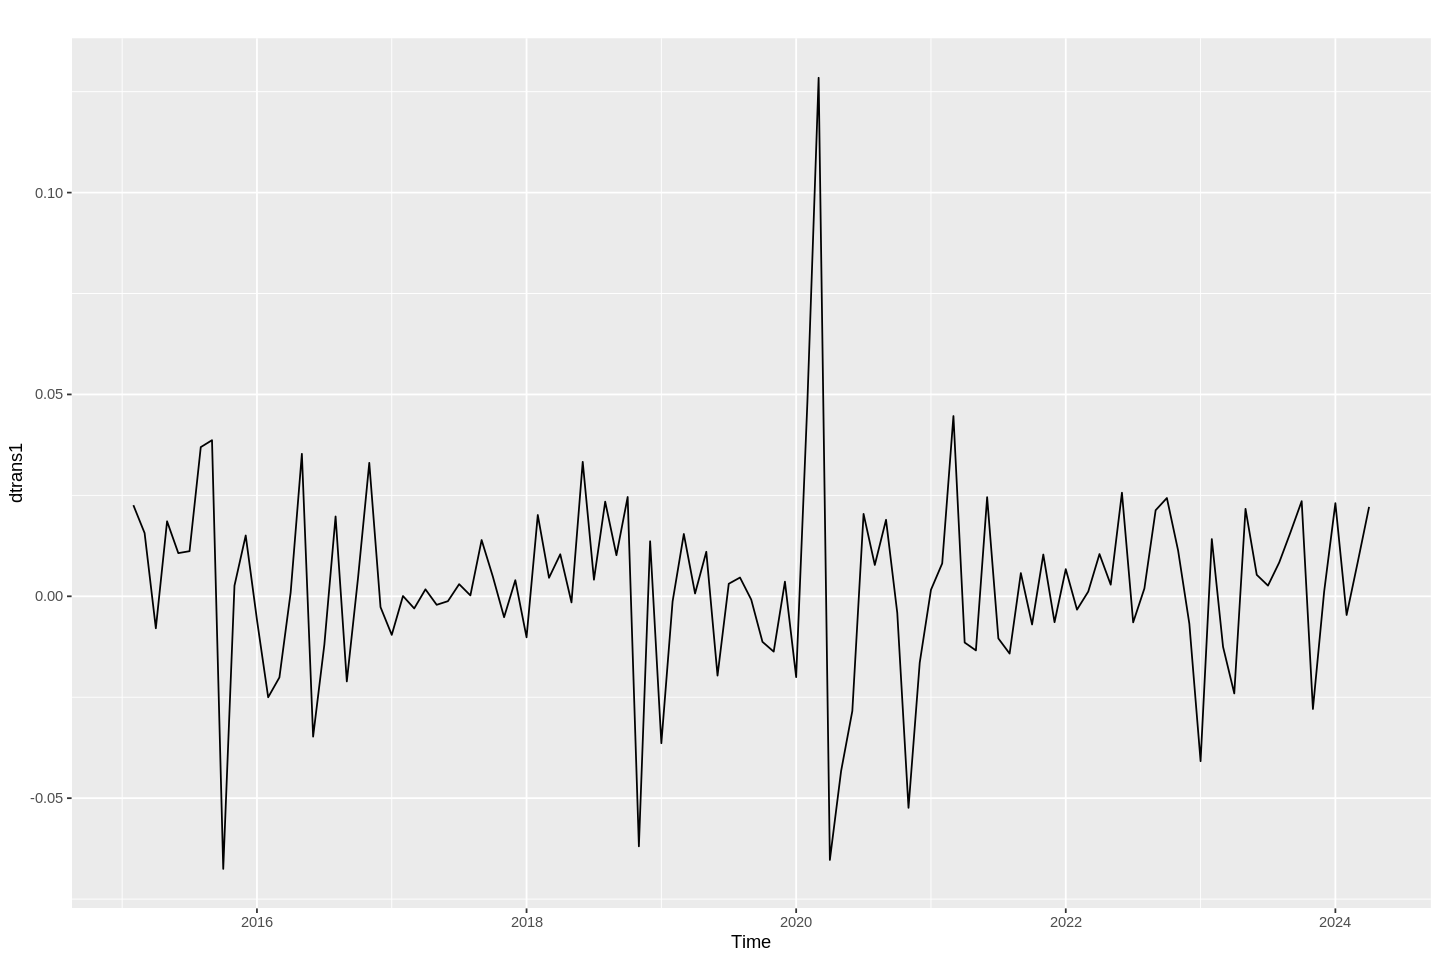

In [ ]:
#Diff 1 with Log-Trans
dtrans1 = diff(log(data), differences=1)
adf.test(dtrans1)
autoplot(dtrans1)

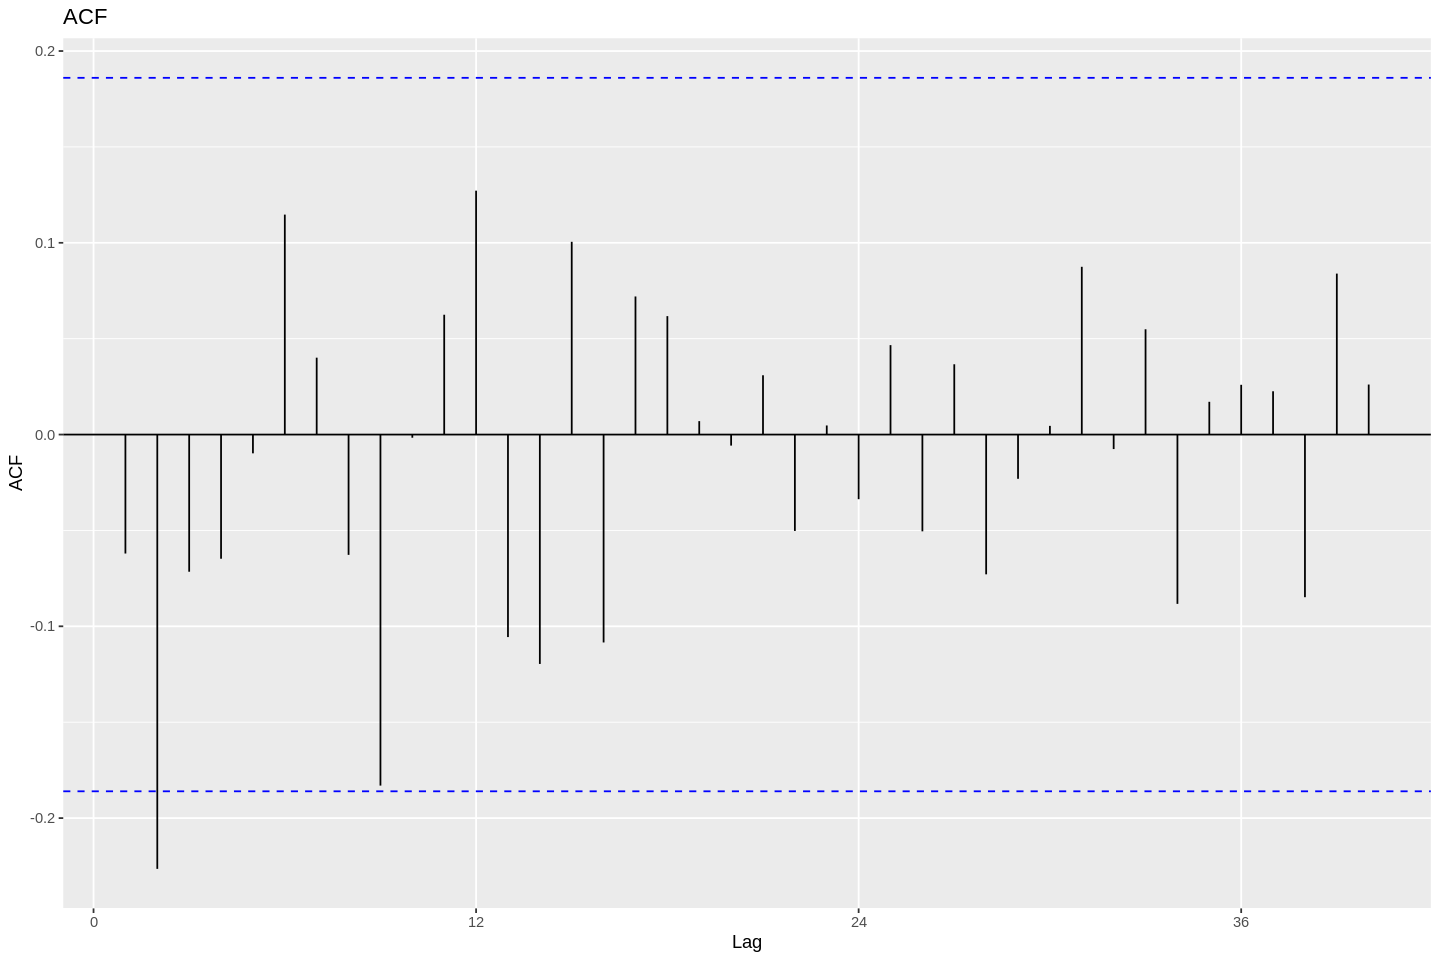

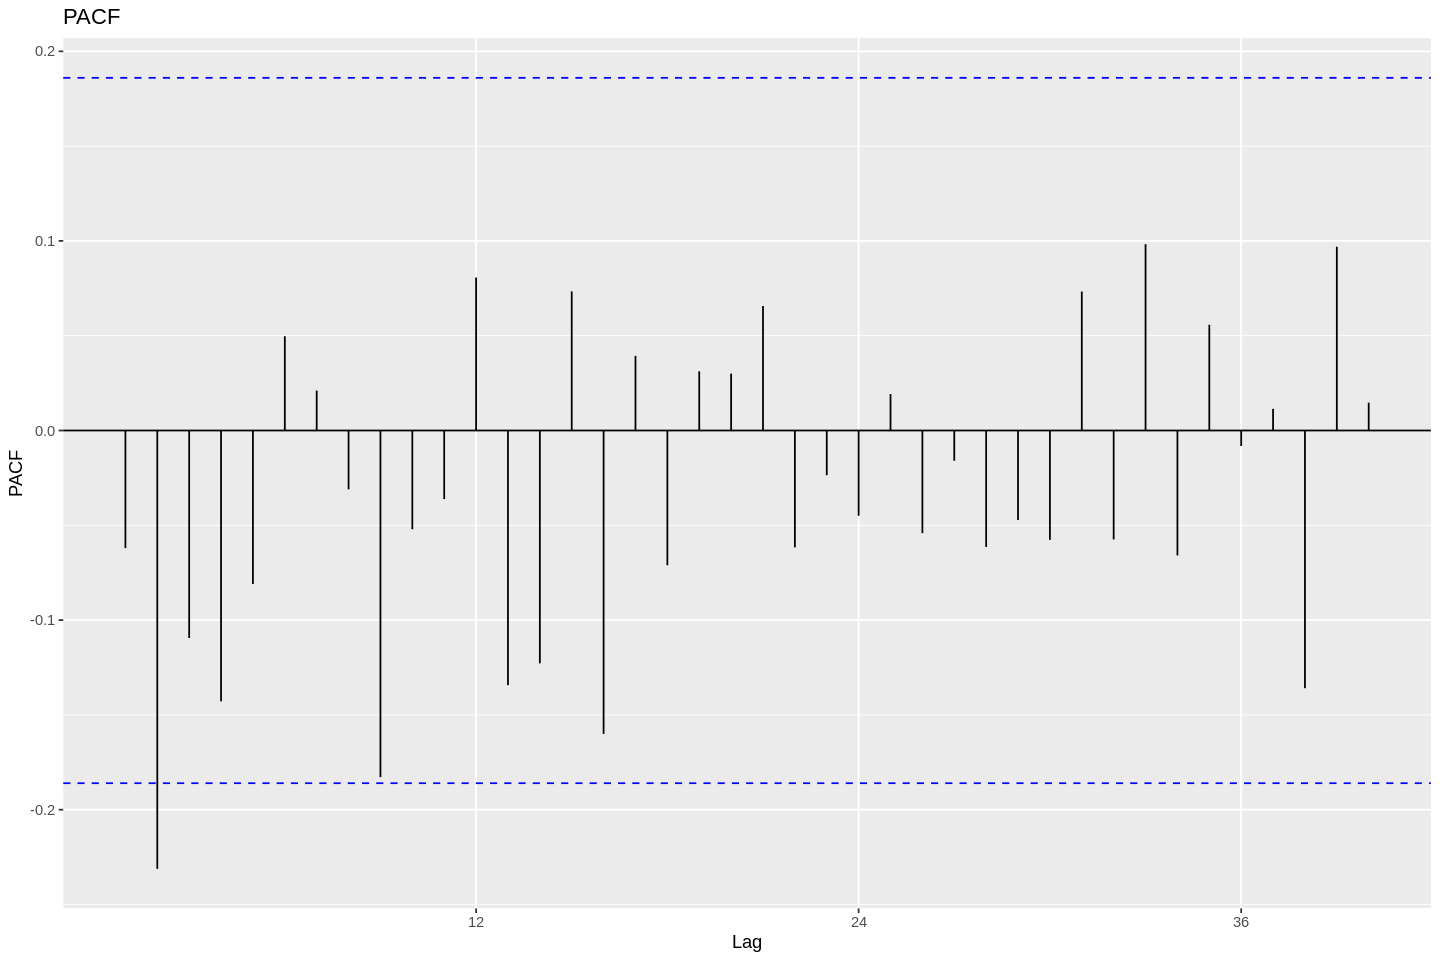

In [ ]:
#Membuat plot ACF dan PACF
ggAcf(ddif1,lag.max = 40) + ggtitle("ACF")
ggPacf(ddif1,lag.max = 40) + ggtitle("PACF")

Model awal ARIMA : ARIMA(2,1,2). Maka, akan dilakukan underfitting model


Underfitting Model

In [ ]:
#ARIMA with constant
#Constant model
c212<-Arima(data,order=c(2,1,2),include.constant = T, lambda = 0)
coeftest(c212)
c211<-Arima(data,order=c(2,1,1),include.constant = T, lambda = 0)
coeftest(c211)
c210<-Arima(data,order=c(2,1,0),include.constant = T, lambda = 0)
coeftest(c210)
c112<-Arima(data,order=c(1,1,2),include.constant = T, lambda = 0)
coeftest(c112)
c111<-Arima(data,order=c(1,1,1),include.constant = T, lambda = 0)
coeftest(c111)
c110<-Arima(data,order=c(1,1,0),include.constant = T, lambda = 0)
coeftest(c110)
c012<-Arima(data,order=c(0,1,2),include.constant = T, lambda = 0)
coeftest(c012)
c011<-Arima(data,order=c(0,1,1),include.constant = T, lambda = 0)
coeftest(c011)


z test of coefficients:

         Estimate  Std. Error z value  Pr(>|z|)    
ar1    0.29513564  0.37192189  0.7935    0.4275    
ar2    0.23022321  0.28622585  0.8043    0.4212    
ma1   -0.49348310  0.34856461 -1.4158    0.1568    
ma2   -0.50651584  0.34782217 -1.4562    0.1453    
drift  0.00154964  0.00022038  7.0316 2.041e-12 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

         Estimate  Std. Error  z value  Pr(>|z|)    
ar1    0.78157015  0.09534642   8.1972 2.461e-16 ***
ar2   -0.10726101  0.09578875  -1.1198    0.2628    
ma1   -0.99999360  0.02664074 -37.5363 < 2.2e-16 ***
drift  0.00154598  0.00021641   7.1438 9.082e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

        Estimate Std. Error z value Pr(>|z|)  
ar1   -0.0677069  0.0925988 -0.7312  0.46467  
ar2   -0.2336813  0.0921163 -2.5368  0.01119 *
drift  0.0021711  0.0017282  1.2563  0.20902  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

         Estimate  Std. Error z value  Pr(>|z|)    
ar1    0.60511204  0.11844619  5.1088 3.243e-07 ***
ma1   -0.80048958  0.15084094 -5.3068 1.115e-07 ***
ma2   -0.19950984  0.14854123 -1.3431    0.1792    
drift  0.00154375  0.00021396  7.2151 5.388e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

        Estimate Std. Error  z value  Pr(>|z|)    
ar1    0.7101942  0.0713672   9.9513 < 2.2e-16 ***
ma1   -0.9999944  0.0255848 -39.0855 < 2.2e-16 ***
drift  0.0015667  0.0002356   6.6498 2.934e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

        Estimate Std. Error z value Pr(>|z|)
ar1   -0.0534260  0.0949500 -0.5627   0.5737
drift  0.0022689  0.0021884  1.0368   0.2998



z test of coefficients:

        Estimate Std. Error z value Pr(>|z|)   
ma1   -0.1510209  0.0952957 -1.5848 0.113021   
ma2   -0.3074521  0.1003020 -3.0653 0.002175 **
drift  0.0020159  0.0012198  1.6526 0.098416 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

        Estimate Std. Error z value Pr(>|z|)
ma1   -0.1055543  0.1363469 -0.7742   0.4388
drift  0.0022468  0.0020611  1.0901   0.2757


In [ ]:
#ARIMA without constant
tc212<-Arima(data,order=c(2,1,2),include.constant = FALSE, lambda = 0)
coeftest(tc212)
tc211<-Arima(data,order=c(2,1,1),include.constant = FALSE, lambda = 0)
coeftest(tc211)
tc210<-Arima(data,order=c(2,1,0),include.constant = FALSE, lambda = 0)
coeftest(tc210)
tc112<-Arima(data,order=c(1,1,2),include.constant = FALSE, lambda = 0)
coeftest(tc112)
tc111<-Arima(data,order=c(1,1,1),include.constant = FALSE, lambda = 0)
coeftest(tc111)
tc110<-Arima(data,order=c(1,1,0),include.constant = FALSE, lambda = 0)
coeftest(tc110)
tc012<-Arima(data,order=c(0,1,2),include.constant = FALSE, lambda = 0)
coeftest(tc012)
tc011<-Arima(data,order=c(0,1,1),include.constant = FALSE, lambda = 0)
coeftest(tc011)


z test of coefficients:

    Estimate Std. Error z value Pr(>|z|)
ar1  0.25285    0.40462  0.6249   0.5320
ar2  0.11612    0.34170  0.3398   0.7340
ma1 -0.35555    0.38558 -0.9221   0.3565
ma2 -0.35322    0.36117 -0.9780   0.3281



z test of coefficients:

    Estimate Std. Error z value Pr(>|z|)  
ar1  0.55841    0.37097  1.5053  0.13225  
ar2 -0.17778    0.13262 -1.3406  0.18006  
ma1 -0.66631    0.38762 -1.7190  0.08562 .
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)  
ar1 -0.058080   0.092928 -0.6250  0.53197  
ar2 -0.225050   0.092509 -2.4327  0.01499 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

    Estimate Std. Error z value Pr(>|z|)  
ar1  0.35361    0.35183  1.0051  0.31486  
ma1 -0.45361    0.35079 -1.2931  0.19597  
ma2 -0.23021    0.12758 -1.8044  0.07117 .
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

     Estimate Std. Error z value  Pr(>|z|)    
ar1  0.670166   0.135511  4.9455 7.597e-07 ***
ma1 -0.859031   0.092285 -9.3085 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)
ar1 -0.045729   0.095111 -0.4808   0.6307



z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)   
ma1 -0.117133   0.093629 -1.2510 0.210923   
ma2 -0.274229   0.095336 -2.8764 0.004022 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



z test of coefficients:

     Estimate Std. Error z value Pr(>|z|)
ma1 -0.086045   0.132487 -0.6495    0.516


Model yang signifikan: ARIMA(1,1,1) dengan konstan dan ARIMA(1,1,1) tanpa konstan.

Diagnostic Checking

In [ ]:
#uji autokorelasi H0 : tidak ada autokorelasi
Box.test(tc111$residuals,type="Ljung")
Box.test(c111$residuals,type="Ljung")


	Box-Ljung test

data:  tc111$residuals
X-squared = 0.23749, df = 1, p-value = 0.626



	Box-Ljung test

data:  c111$residuals
X-squared = 0.71048, df = 1, p-value = 0.3993


In [ ]:
#uji homoskedastisitas H0 : homoskedasitisitas terpenuhi (variansi residual konstan terhadap waktu)
Box.test((tc111$residuals)^2,type="Ljung")
Box.test((c111$residuals)^2,type="Ljung")


	Box-Ljung test

data:  (tc111$residuals)^2
X-squared = 2.5842, df = 1, p-value = 0.1079



	Box-Ljung test

data:  (c111$residuals)^2
X-squared = 1.4452, df = 1, p-value = 0.2293


In [ ]:
 #uji normalitas H0 : residual berdistribusi normal
jarque.bera.test(tc111$residuals)
jarque.bera.test(c111$residuals)


	Jarque Bera Test

data:  tc111$residuals
X-squared = 252.74, df = 2, p-value < 2.2e-16



	Jarque Bera Test

data:  c111$residuals
X-squared = 272.79, df = 2, p-value < 2.2e-16



	Ljung-Box test

data:  Residuals from ARIMA(1,1,1)
Q* = 18.844, df = 20, p-value = 0.532

Model df: 2.   Total lags used: 22



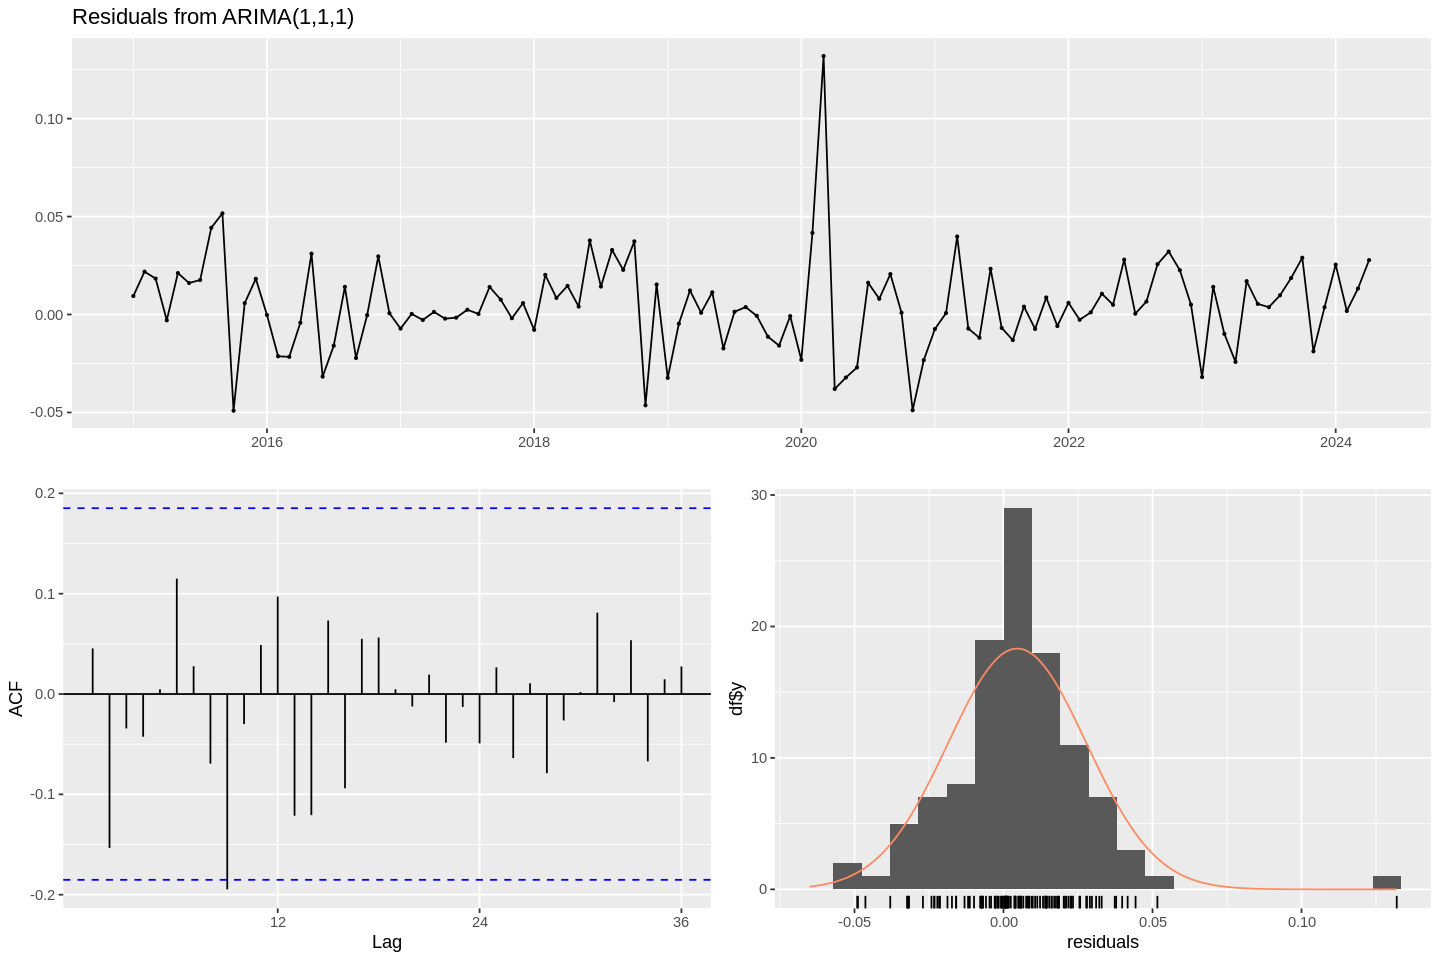

In [ ]:
checkresiduals(tc111)


	Ljung-Box test

data:  Residuals from ARIMA(1,1,1) with drift
Q* = 17.258, df = 20, p-value = 0.6361

Model df: 2.   Total lags used: 22



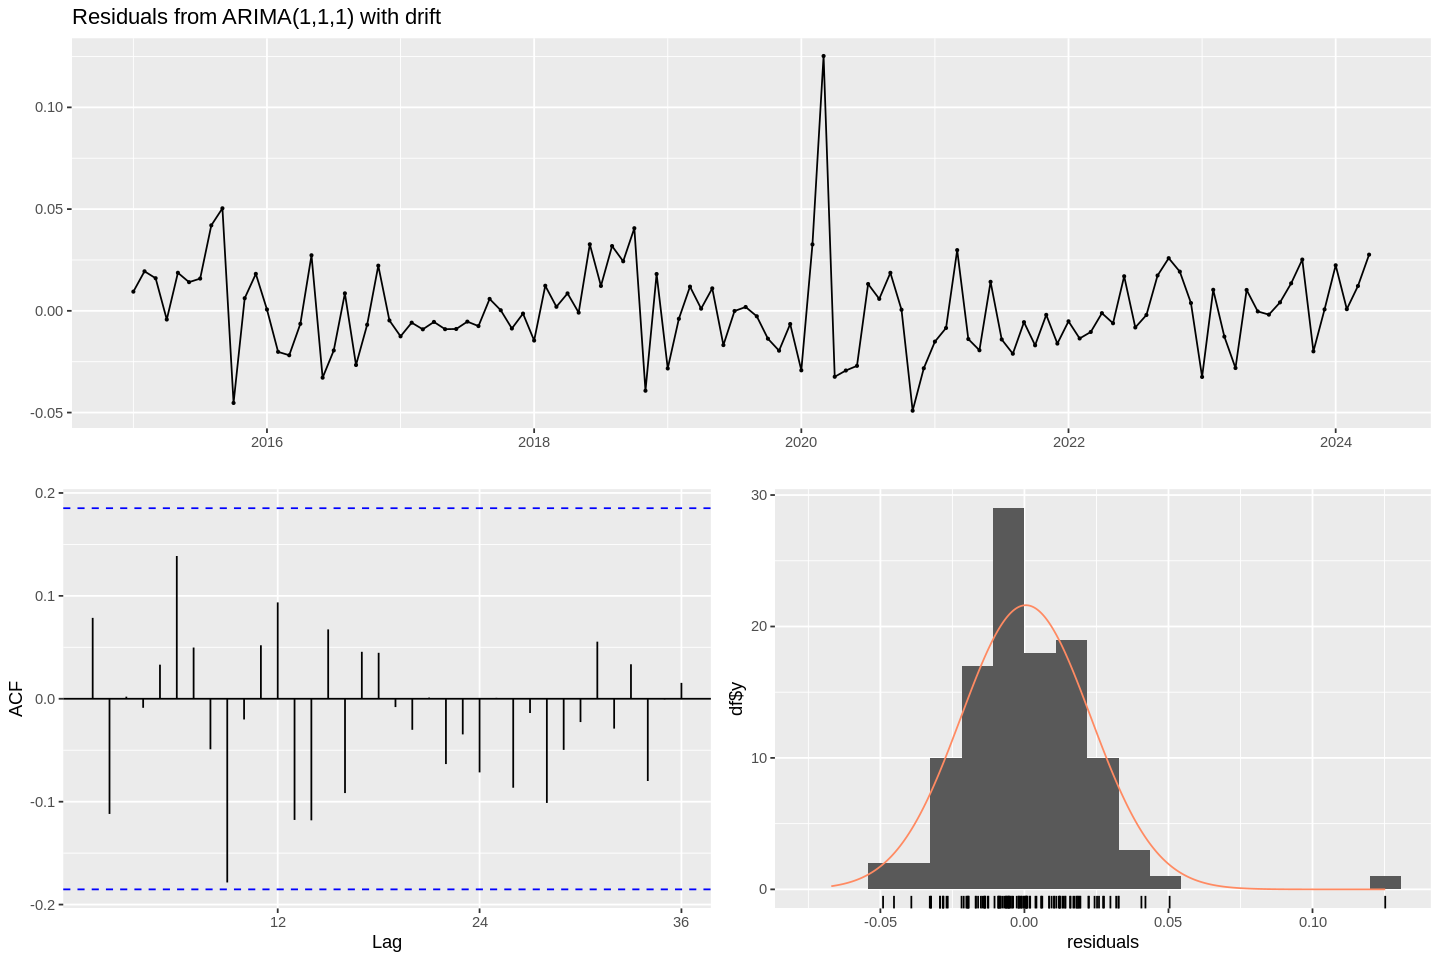

In [ ]:
checkresiduals(c111)

In [ ]:
#best model selection
mod_tc111 = data.frame(Model = "tc111", LogLik = logLik(tc111), AIC = AIC(tc111), BIC = BIC(tc111))
mod_c111 = data.frame(Model = "c111", LogLik = logLik(c111), AIC = AIC(c111), BIC = BIC(c111))
model_selection = rbind(mod_tc111, mod_c111)
model_selection

Model,LogLik,AIC,BIC
<chr>,<dbl>,<dbl>,<dbl>
tc111,257.8582,-509.7163,-501.5877
c111,262.1392,-516.2783,-505.4402


,ME,RMSE,MAE,MPE,MAPE,MASE,ACF1
Training set,9.676024,327.6876,232.1609,0.02577916,1.612595,0.4256019,0.06784446


         Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
May 2024       16020.73 15556.77 16498.53 15316.63 16757.20
Jun 2024       15899.75 15334.65 16485.68 15043.67 16804.55
Jul 2024       15821.57 15212.33 16455.21 14899.37 16800.85
Aug 2024       15773.44 15142.88 16430.26 14819.35 16788.95
Sep 2024       15746.49 15105.00 16415.23 14776.06 16780.66

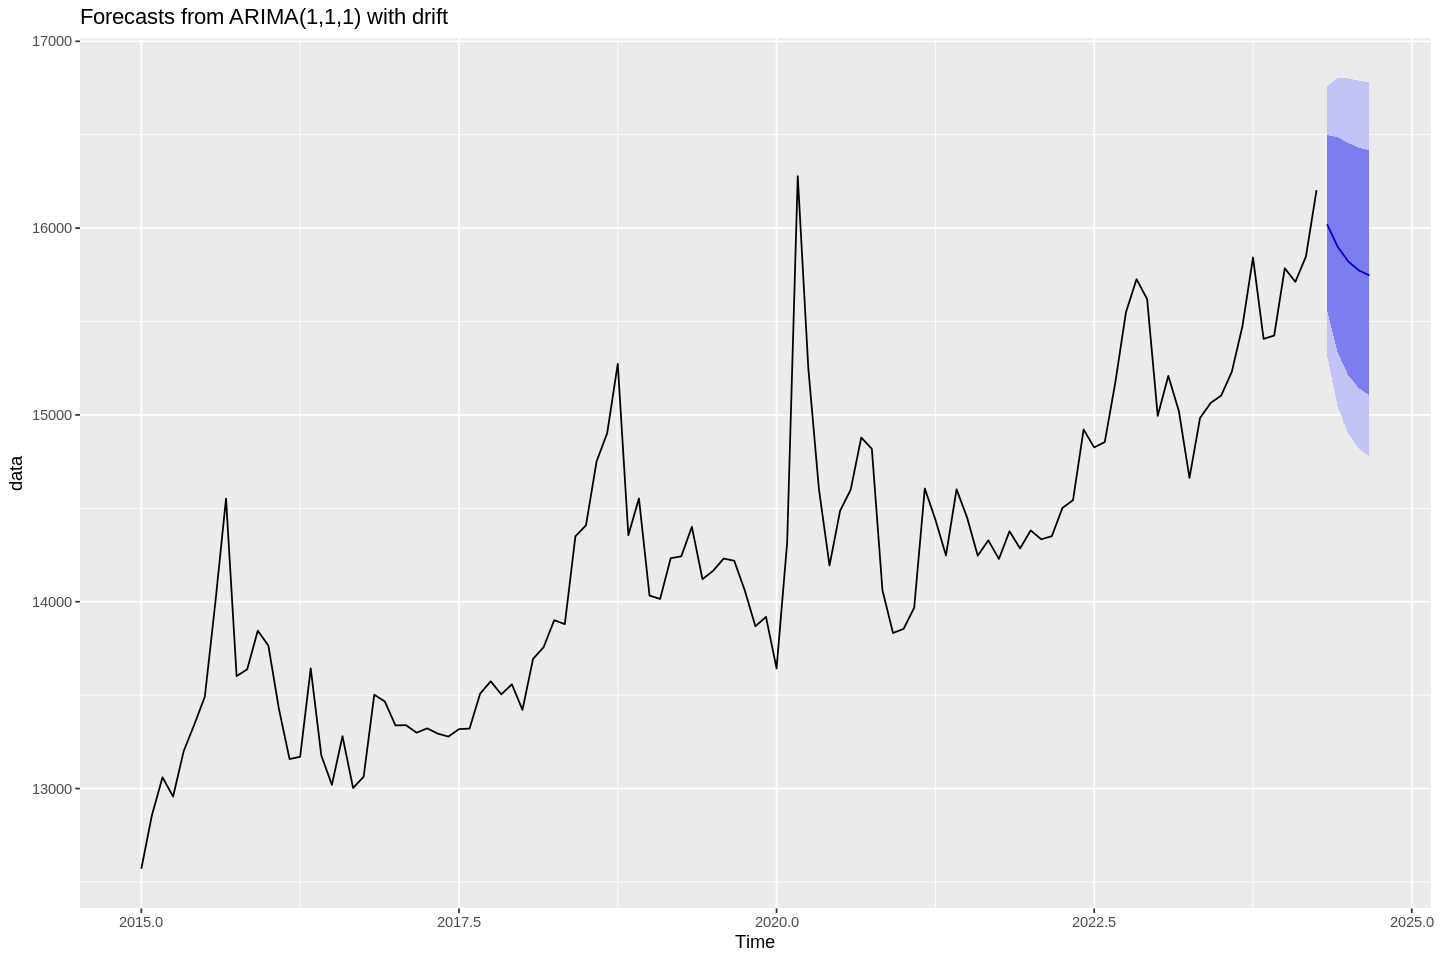

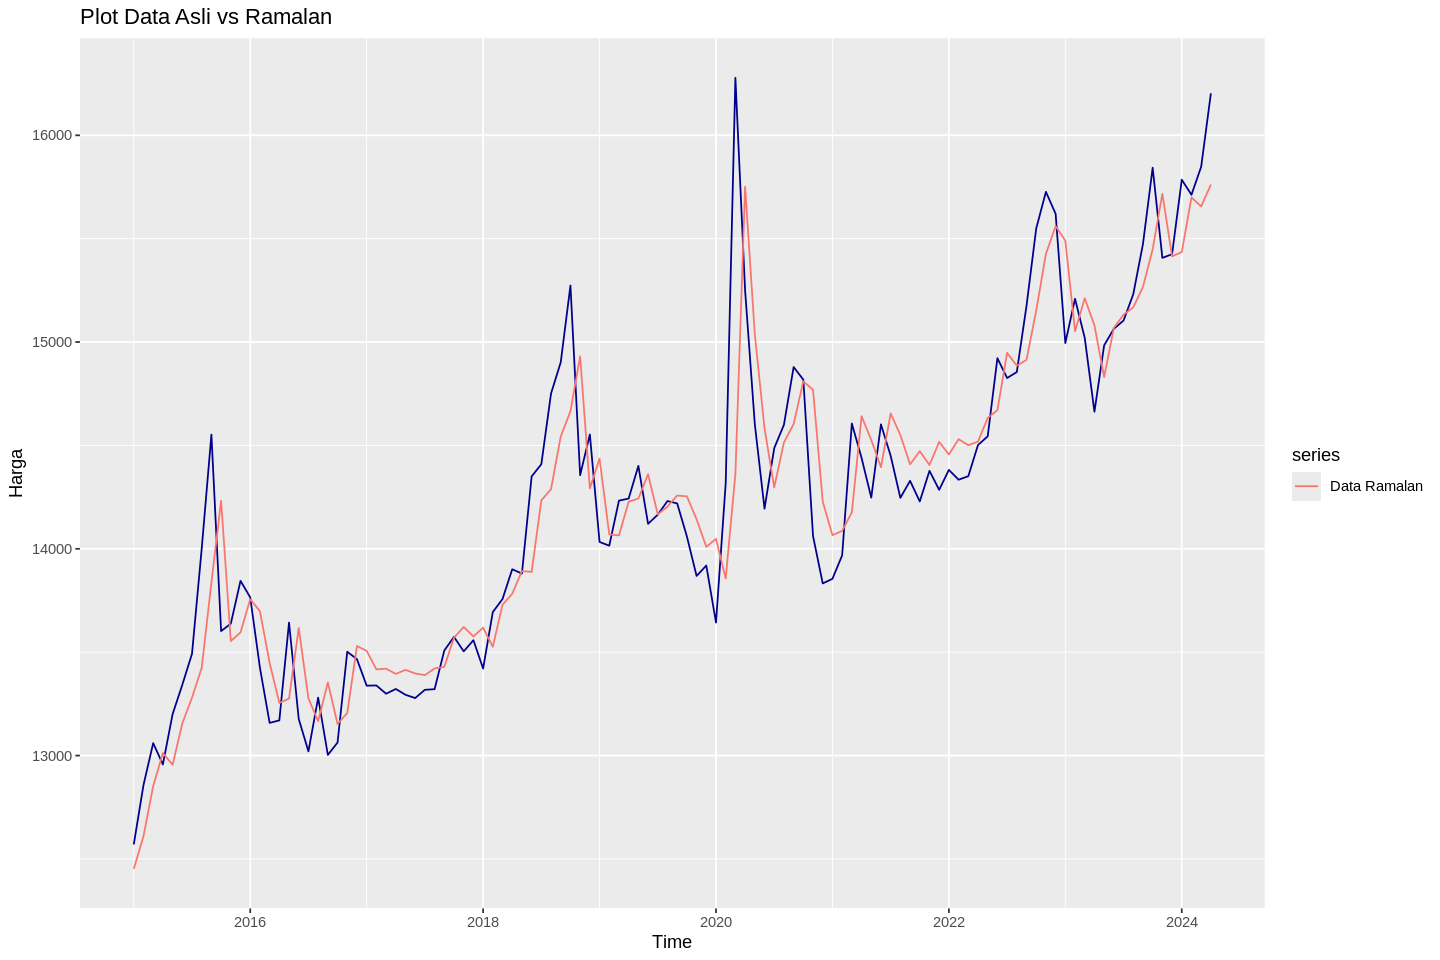

In [ ]:
#Forecast and Accuracy
accuracy(c111)
forecast(c111,5)
autoplot(forecast(c111,5))
##Plot##
autoplot(c111$x, col="darkblue") +
  autolayer(fitted(c111), series = "Data Ramalan") +
  ylab("Harga") +
  ggtitle("Plot Data Asli vs Ramalan")

# ARCH/GARCH

In [ ]:
library(rugarch)

Loading required package: parallel


Attaching package: ‘rugarch’


The following object is masked from ‘package:stats’:

    sigma




In [ ]:
model_arima = auto.arima(data, d = 1, max.p = 4, max.q = 4, seasonal = FALSE)
model_arima

Series: data 
ARIMA(0,1,0) 

sigma^2 = 128119:  log likelihood = -810.22
AIC=1622.44   AICc=1622.48   BIC=1625.15

In [ ]:
garch_spec = ugarchspec(
  mean.model = list(armaOrder = c(1,1)),
  variance.model = list(model="sGARCH", garchOrder = c(1,1)),
  distribution.model="norm")
model_garch = ugarchfit(spec = garch_spec, data = data, include.mean = FALSE)
model_garch


*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: sGARCH(1,1)
Mean Model	: ARFIMA(1,0,1)
Distribution	: norm 

Optimal Parameters
------------------------------------
          Estimate  Std. Error  t value Pr(>|t|)
mu     12638.48370  3.0912e+02  40.8859 0.000000
ar1        1.00000  1.4715e-02  67.9587 0.000000
ma1       -0.12684  1.6399e-01  -0.7735 0.439229
omega  12892.15540  1.0080e+04   1.2790 0.200893
alpha1     0.51577  1.5842e-01   3.2557 0.001131
beta1      0.48323  9.9777e-02   4.8431 0.000001

Robust Standard Errors:
          Estimate  Std. Error  t value Pr(>|t|)
mu     12638.48370  1.5943e+02 79.27361 0.000000
ar1        1.00000  1.9649e-02 50.89262 0.000000
ma1       -0.12684  2.7125e-01 -0.46763 0.640047
omega  12892.15540  1.8817e+04  0.68513 0.493261
alpha1     0.51577  2.7412e-01  1.88157 0.059894
beta1      0.48323  1.6076e-0

In [ ]:
f_garch = ugarchforecast(fitORspec = model_garch, n.ahead=5)
f_garch


*------------------------------------*
*       GARCH Model Forecast         *
*------------------------------------*
Model: sGARCH
Horizon: 5
Roll Steps: 0
Out of Sample: 0

0-roll forecast [T0=Apr 2024]:
    Series Sigma
T+1  16156 333.9
T+2  16156 352.5
T+3  16156 370.1
T+4  16156 387.0
T+5  16156 403.1



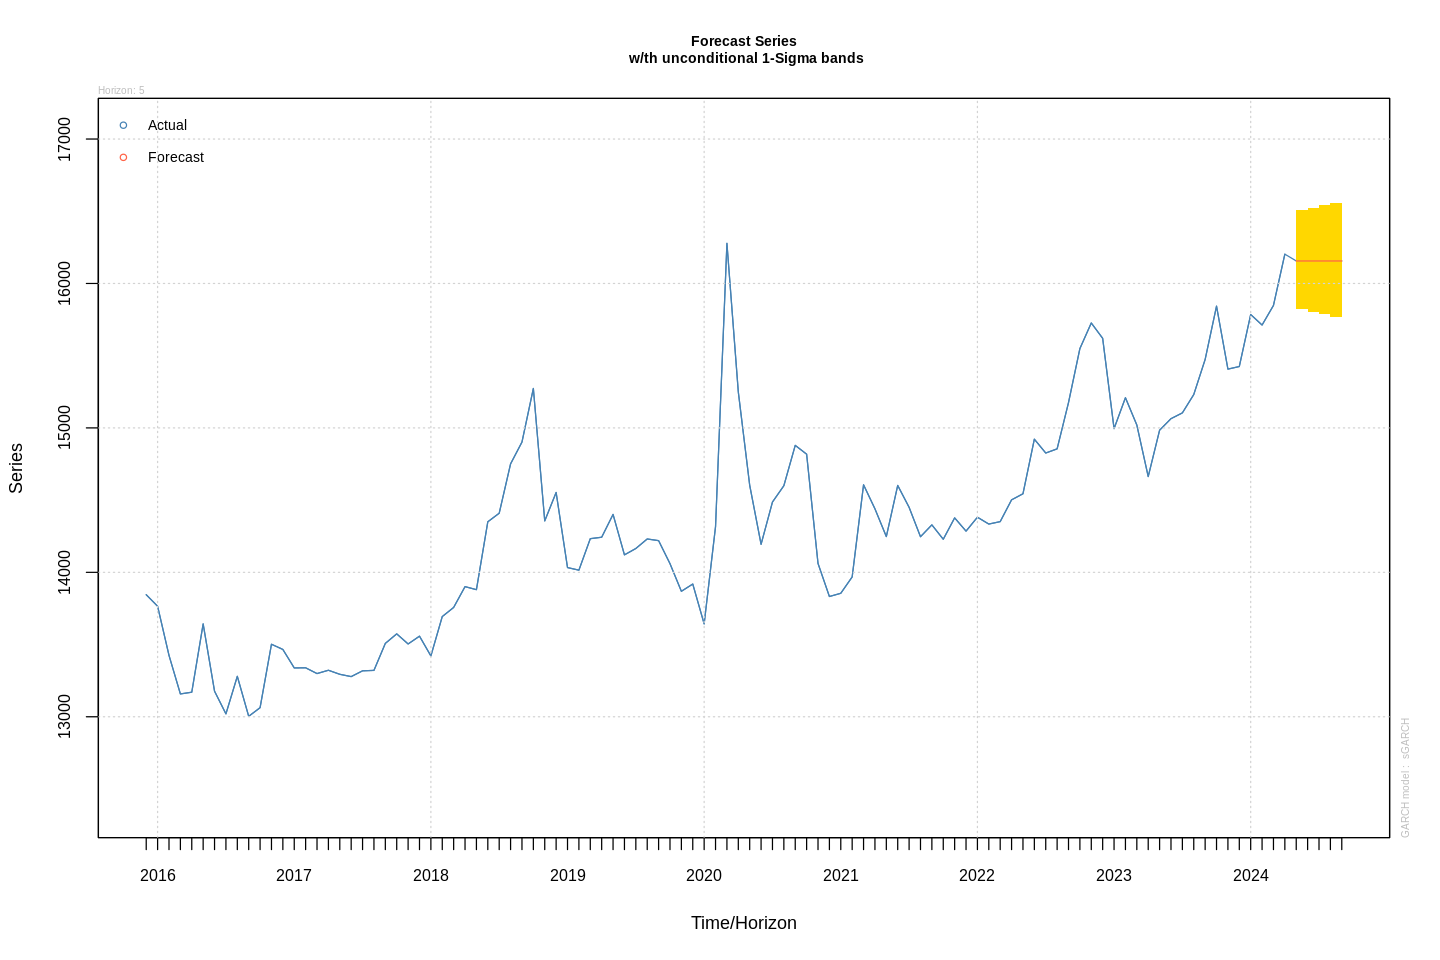

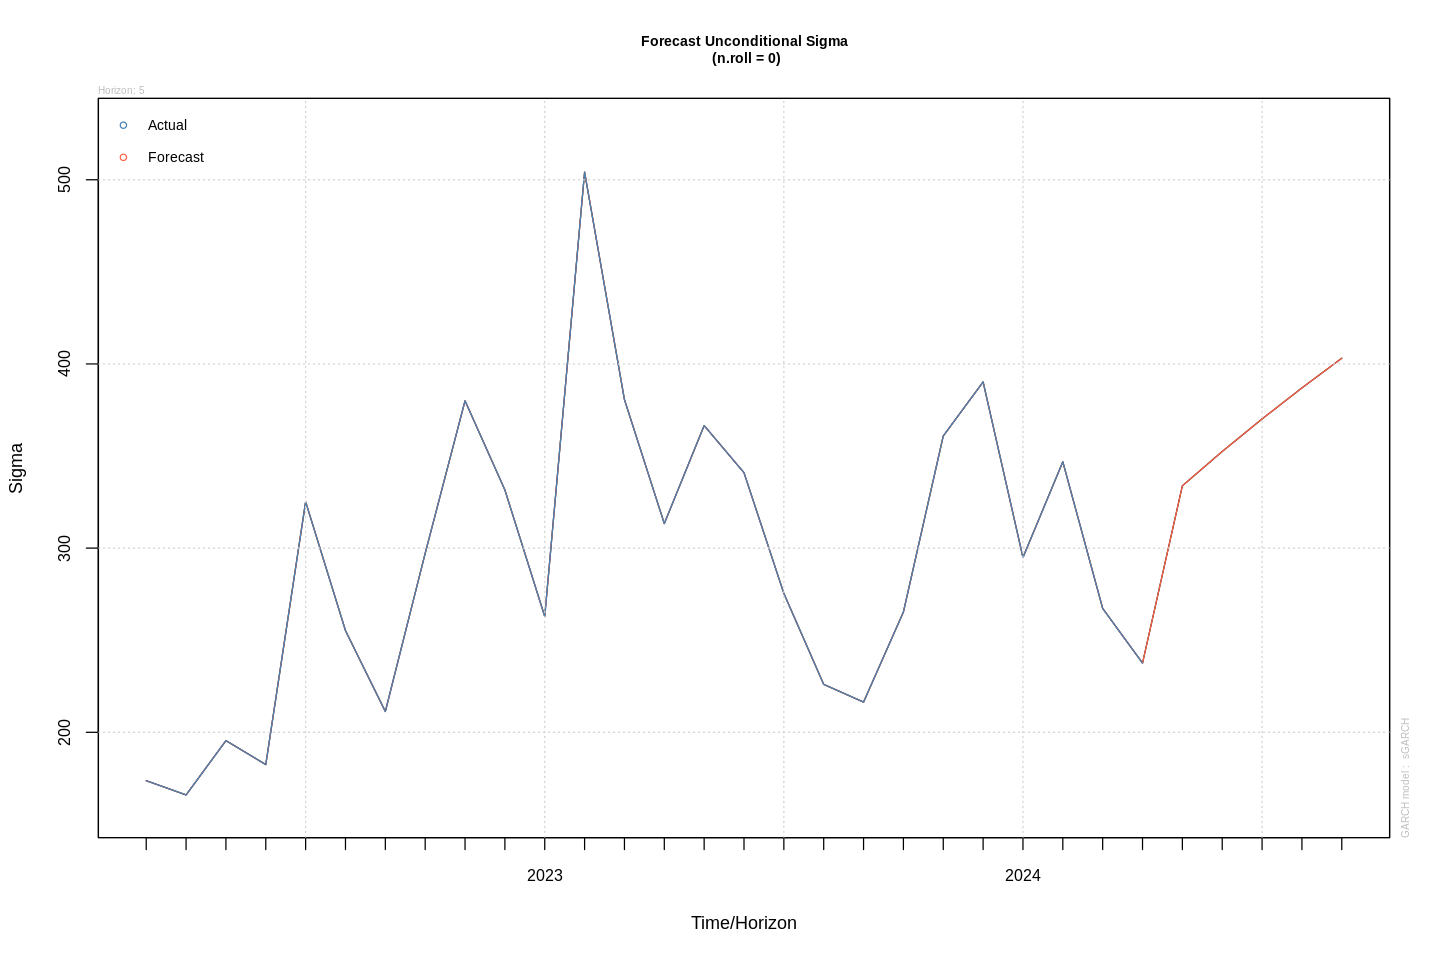

In [ ]:
plot(f_garch, which = 1 )
plot(f_garch, which = 3 )


In [ ]:
f_garch@model

$modelinc
      mu       ar       ma   arfima    archm    mxreg    omega    alpha 
       1        1        1        0        0        0        1        1 
    beta    gamma     eta1     eta2    delta   lambda    vxreg     skew 
       1        0        0        0        0        0        0        0 
   shape ghlambda       xi      aux      aux      aux 
       0        0        0        0        1       NA 

$modeldesc
$modeldesc$distribution
[1] "norm"

$modeldesc$distno
[1] 1

$modeldesc$vmodel
[1] "sGARCH"


$modeldata
$modeldata$T
[1] 112

$modeldata$data
  [1] 12570.00 12857.00 13060.00 12957.00 13200.00 13342.00 13492.00 14000.00
  [9] 14552.00 13602.00 13638.00 13845.00 13765.00 13425.00 13158.00 13170.00
 [17] 13643.00 13177.00 13020.00 13280.00 13003.00 13063.00 13502.00 13466.00
 [25] 13338.00 13339.00 13299.00 13322.00 13294.00 13278.00 13318.00 13321.00
 [33] 13508.00 13574.00 13504.00 13558.00 13421.00 13694.00 13757.00 13901.00
 [41] 13880.00 14350.00 14409.20 14751.00 1

In [ ]:
fitting <- ts(model_garch@fit$fitted.values, start=c(2015,1), frequency = 12)

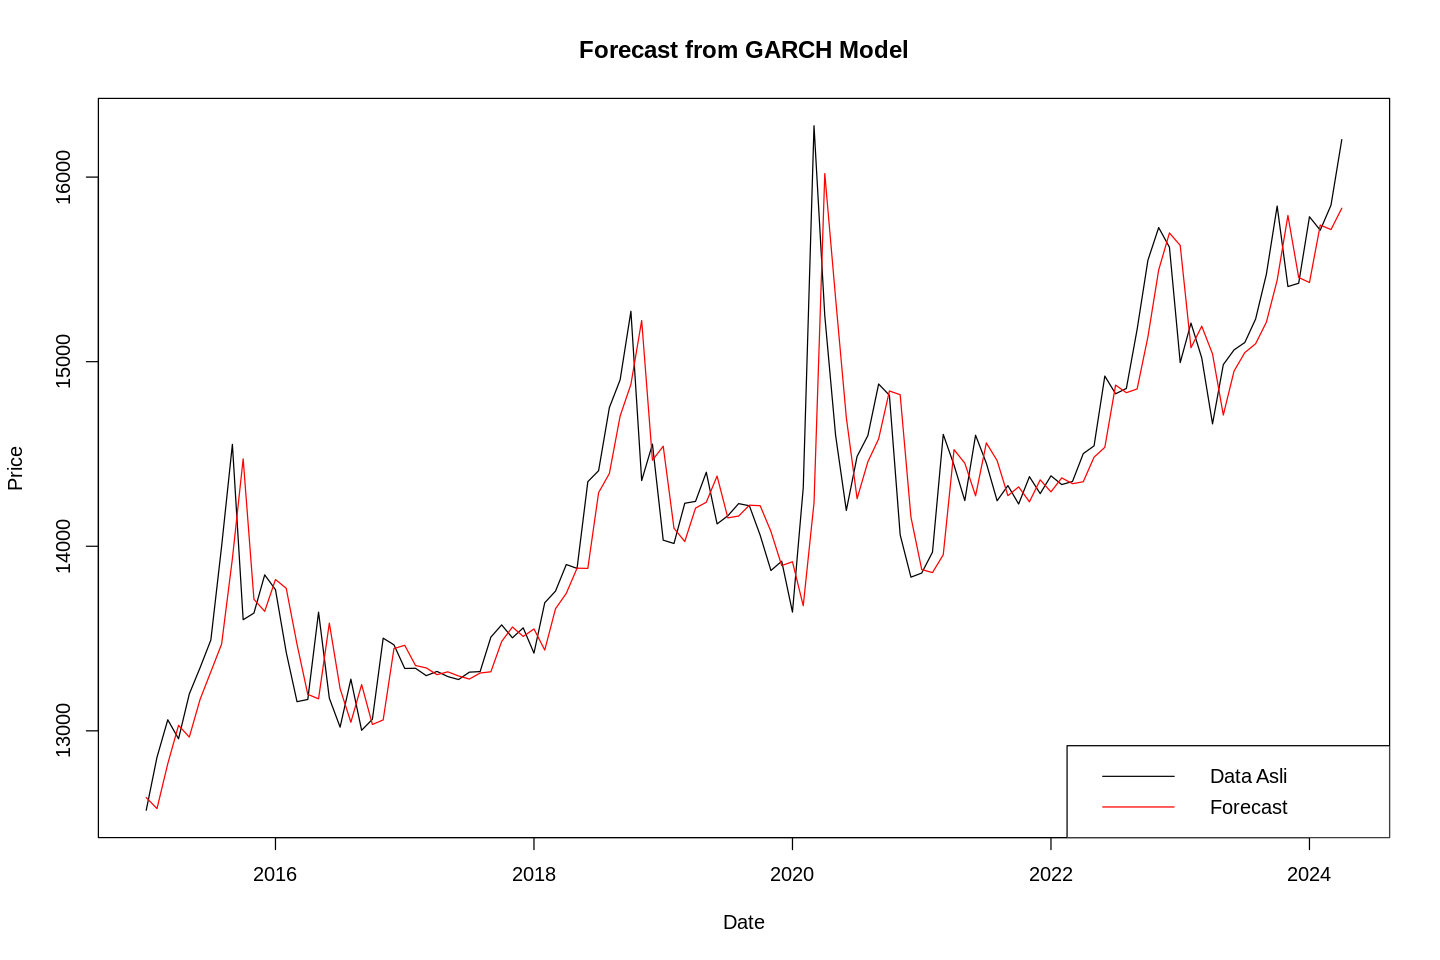

In [ ]:
# Plot data asli
plot(data, type = "l", main = "Forecast from GARCH Model", ylab = "Price", xlab = "Date", ylim = range(data))
# Plot hasil forecast (sigma) dari model GARCH
lines(fitting, col = "red")
# Menambahkan legenda
legend("bottomright", legend = c("Data Asli", "Forecast"), col = c("black", "red"), lty = c(1, 1))


In [ ]:
# Hitung selisih antara data asli dan forecast
selisih <- data - model_garch@fit$fitted.values

# Hitung RMSE
rmse <- sqrt(mean(selisih^2))

# Tampilkan RMSE
print(paste("RMSE:", rmse))


[1] "RMSE: 355.376031915825"


Menemukan RMSE yang lebih kecil

In [ ]:
garch_spec2 = ugarchspec(
  mean.model = list(armaOrder = c(3,2)),
  variance.model = list(model="sGARCH", garchOrder = c(1,1)),
  distribution.model="norm")
model_garch2 = ugarchfit(spec = garch_spec2, data = data, include.mean = FALSE)

# Hitung selisih antara data asli dan forecast
selisih <- data - model_garch2@fit$fitted.values

# Hitung RMSE
rmse <- sqrt(mean(selisih^2))

# Tampilkan RMSE
print(paste("RMSE:", rmse))


[1] "RMSE: 322.237222091875"


In [ ]:
f_garch2 = ugarchforecast(fitORspec = model_garch2, n.ahead=5)
f_garch2


*------------------------------------*
*       GARCH Model Forecast         *
*------------------------------------*
Model: sGARCH
Horizon: 5
Roll Steps: 0
Out of Sample: 0

0-roll forecast [T0=Apr 2024]:
    Series Sigma
T+1  16304 180.8
T+2  16362 183.8
T+3  16454 186.7
T+4  16542 189.6
T+5  16642 192.4



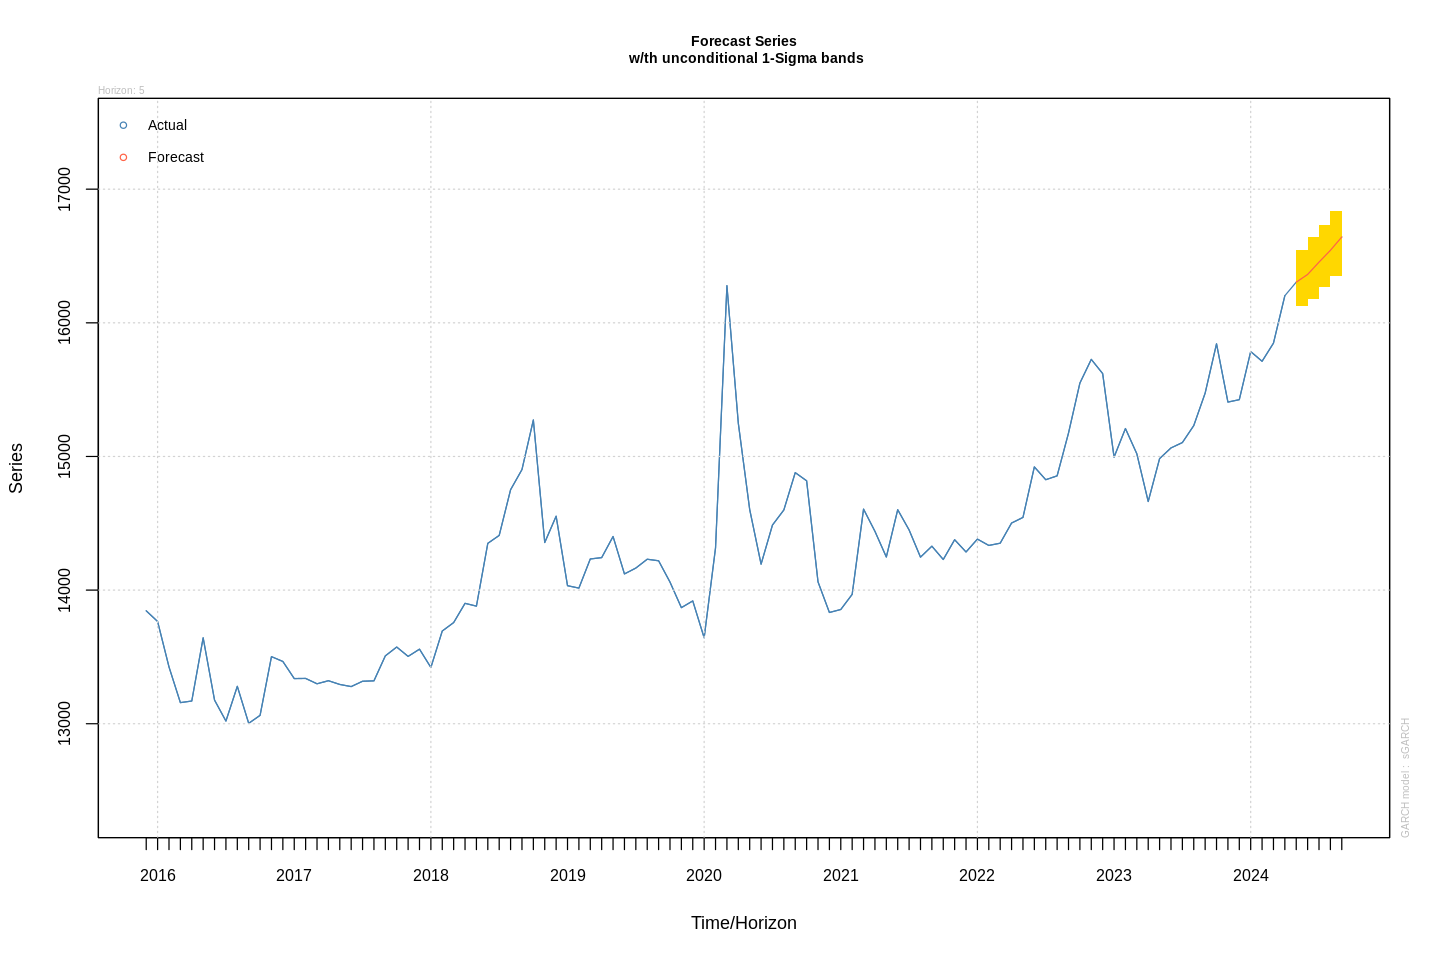

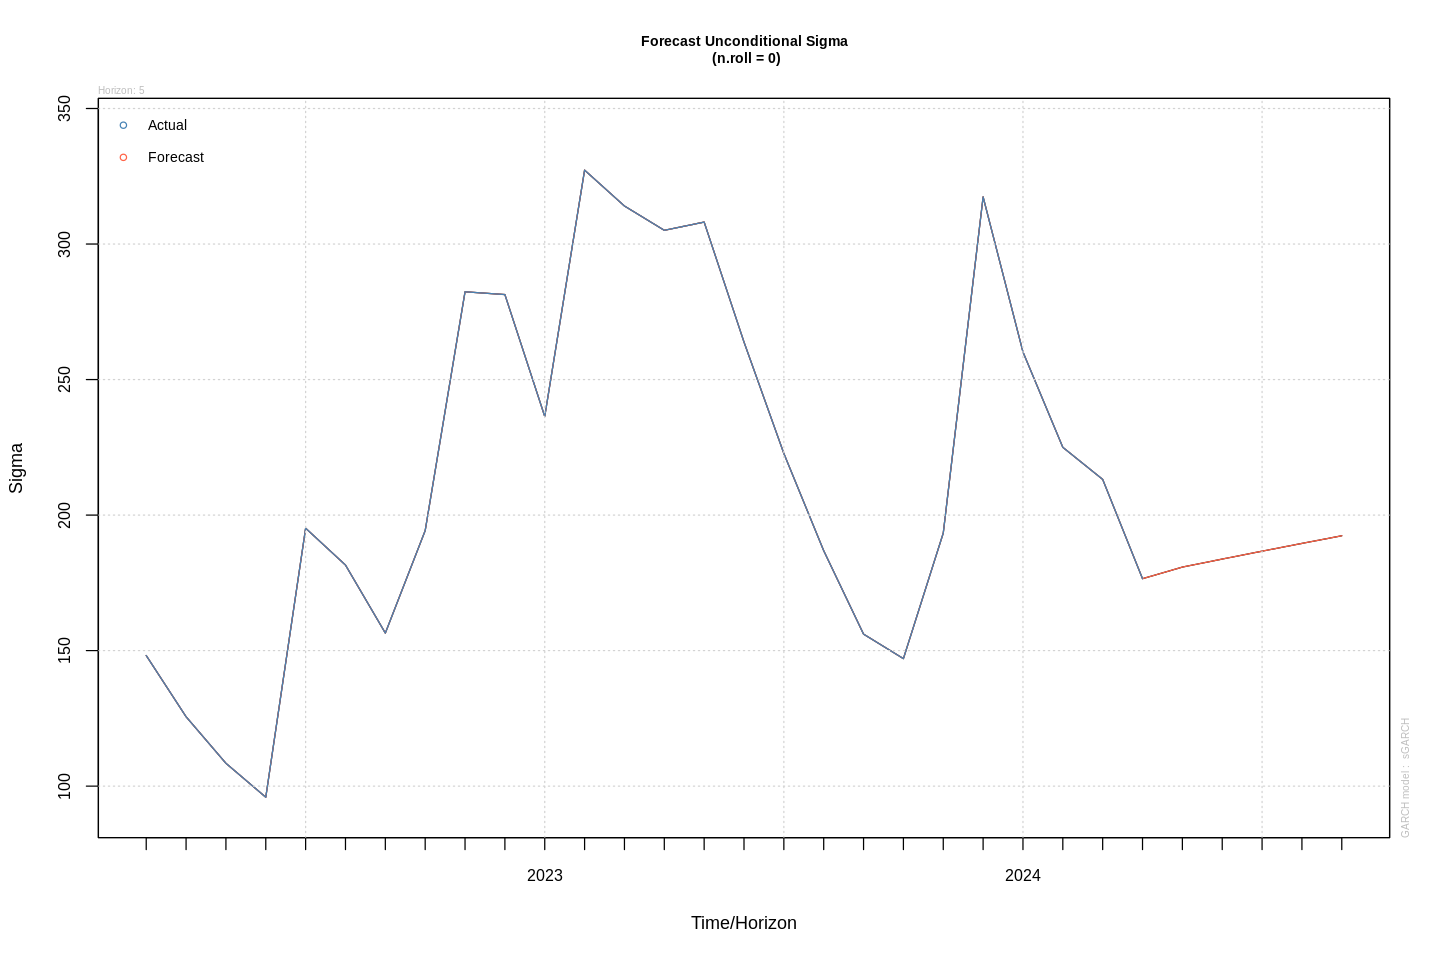

In [ ]:
plot(f_garch2, which = 1 )
plot(f_garch2, which = 3 )


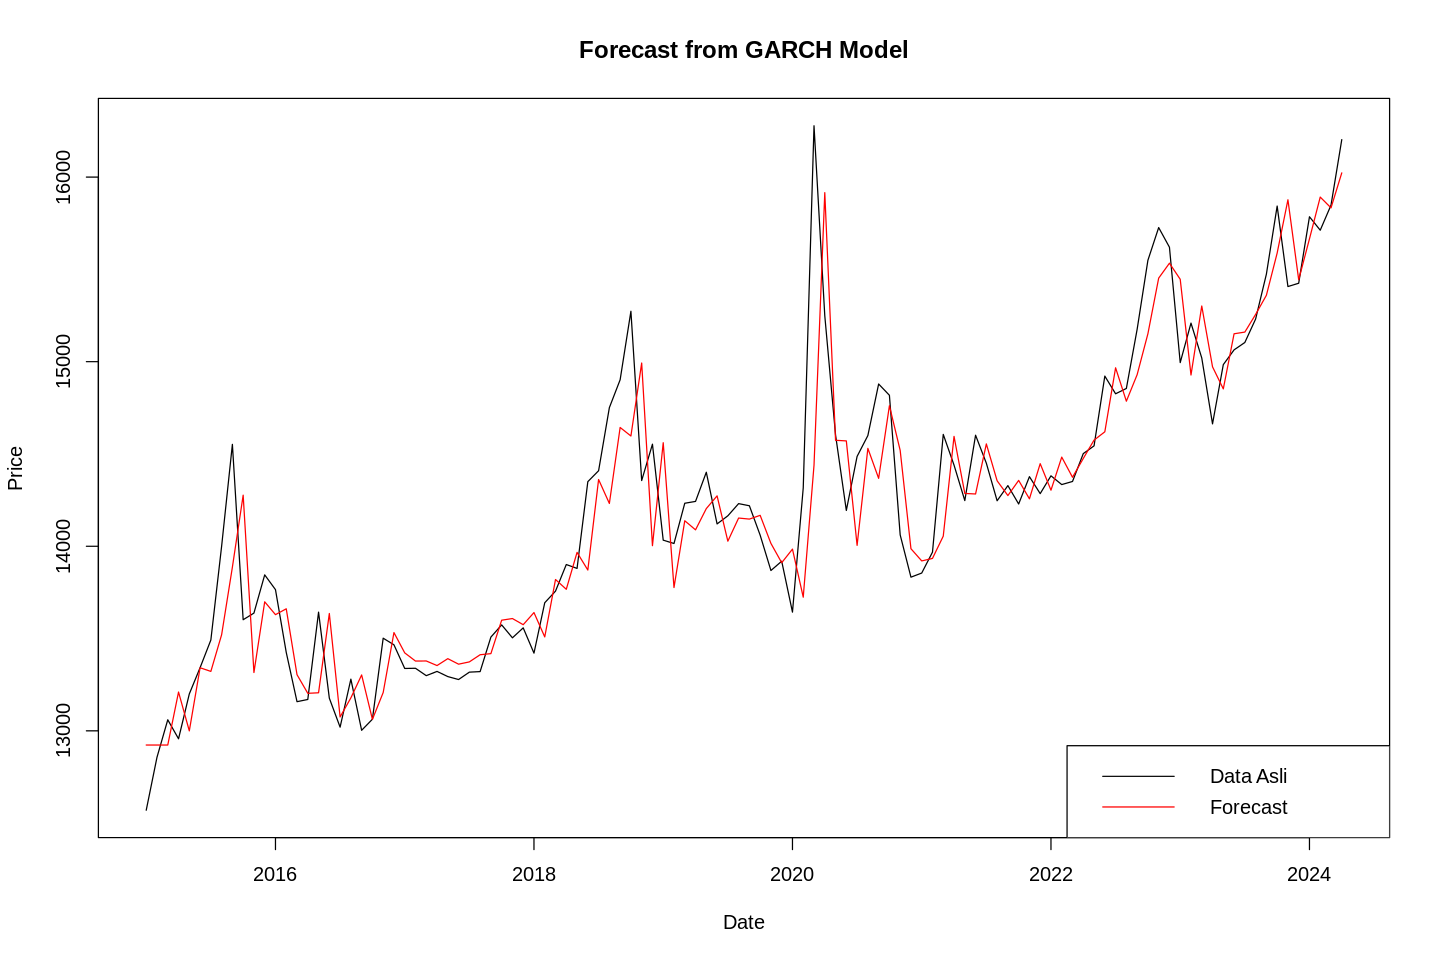

In [ ]:
fitting2 <- ts(model_garch2@fit$fitted.values, start=c(2015,1), frequency = 12)
# Plot data asli
plot(data, type = "l", main = "Forecast from GARCH Model", ylab = "Price", xlab = "Date", ylim = range(data))
# Plot hasil forecast (sigma) dari model GARCH
lines(fitting2, col = "red")
# Menambahkan legenda
legend("bottomright", legend = c("Data Asli", "Forecast"), col = c("black", "red"), lty = c(1, 1))


# Long Short-Term Memory

In [ ]:
library(dplyr)
library(keras)

In [ ]:
rp <- data.frame(
  date = index(df),
  close = as.numeric(df$`IDR=X.Close`))
head(rp)

,date,close
,<date>,<dbl>
1,2015-01-01,12390
2,2015-01-02,12390
3,2015-01-05,12480
4,2015-01-06,12625
5,2015-01-07,12635
6,2015-01-08,12720


In [ ]:
cleaned_data <- na.omit(rp$close)

In [ ]:
#standarized the data using scale()
price <- scale(cleaned_data)
price <- data.frame(price)
head(price)

,price
,<dbl>
1,-2.245343
2,-2.245343
3,-2.133906
4,-1.954370
5,-1.941988
6,-1.836743


In [ ]:
#define the train and test split
split_data <- function(stock, lookback) {
  data_raw <- as.matrix(stock) # convert to matrix
  data <- array(dim = c(0, lookback, ncol(data_raw)))

  # create all possible sequences of length lookback
  for (index in 1:(nrow(data_raw) - lookback)) {
    data <- rbind(data, data_raw[index:(index + lookback - 1), ])
  }

  test_set_size <- round(0.2 * nrow(data))
  train_set_size <- nrow(data) - test_set_size

  x_train <- data[1:train_set_size, 1:(lookback - 1), drop = FALSE]
  y_train <- data[1:train_set_size, lookback, drop = FALSE]

  x_test <- data[(train_set_size + 1):nrow(data), 1:(lookback - 1), drop = FALSE]
  y_test <- data[(train_set_size + 1):nrow(data), lookback, drop = FALSE]

  return(list(x_train = x_train, y_train = y_train,
              x_test = x_test, y_test = y_test))
}

In [ ]:
#divide data into train and test
lookback <- 8 # choose sequence length
split_data <- split_data(price, lookback) # assuming "price" is a data frame
x_train <- split_data$x_train
y_train <- split_data$y_train
x_test <- split_data$x_test
y_test <- split_data$y_test

cat(paste('x_train.shape = ', dim(x_train), '\n'))
cat(paste('y_train.shape = ', dim(y_train), '\n'))
cat(paste('x_test.shape = ', dim(x_test), '\n'))
cat(paste('y_test.shape = ', dim(y_test), '\n'))

x_train.shape =  1938 
 x_train.shape =  7 
y_train.shape =  1938 
 y_train.shape =  1 
x_test.shape =  484 
 x_test.shape =  7 
y_test.shape =  484 
 y_test.shape =  1 


In [ ]:
#decide hyperparameters
input_dim <- 1
hidden_dim <- 32
num_layers <- 2
output_dim <- 1
num_epochs <- 200

In [ ]:
# Reshape the training and test data to have a 3D tensor shape
x_train <- array_reshape(x_train, c(dim(x_train)[1], lookback-1, input_dim))
x_test <- array_reshape(x_test, c(dim(x_test)[1], lookback-1, input_dim))

# Define the LSTM model using Keras
model <- keras_model_sequential() %>%
  layer_lstm(units = hidden_dim, return_sequences = TRUE, input_shape = c(lookback-1, input_dim)) %>%
  layer_lstm(units = hidden_dim) %>%
  layer_dense(units = output_dim)

In [ ]:
# Compile the model using the mean squared error loss and the Adam optimizer
model %>% compile(loss = "mean_squared_error", optimizer = optimizer_adam(learning_rate = 0.01))
# Train the model on the training data
history <- model %>% fit(x_train, y_train, epochs = num_epochs, batch_size = 16, validation_data = list(x_test, y_test))

In [ ]:
# Extract predictions from the stimated model
y_train_pred <- model %>% predict(x_train)
y_test_pred <- model %>% predict(x_test)

In [ ]:
# Rescale the predictions and original values
y_train_pred_orig <- y_train_pred * sd(cleaned_data) + mean(cleaned_data)
y_train_orig <- y_train * sd(cleaned_data) + mean(cleaned_data)
y_test_pred_orig <- y_test_pred * sd(cleaned_data) + mean(cleaned_data)
y_test_orig <- y_test * sd(cleaned_data) + mean(cleaned_data)

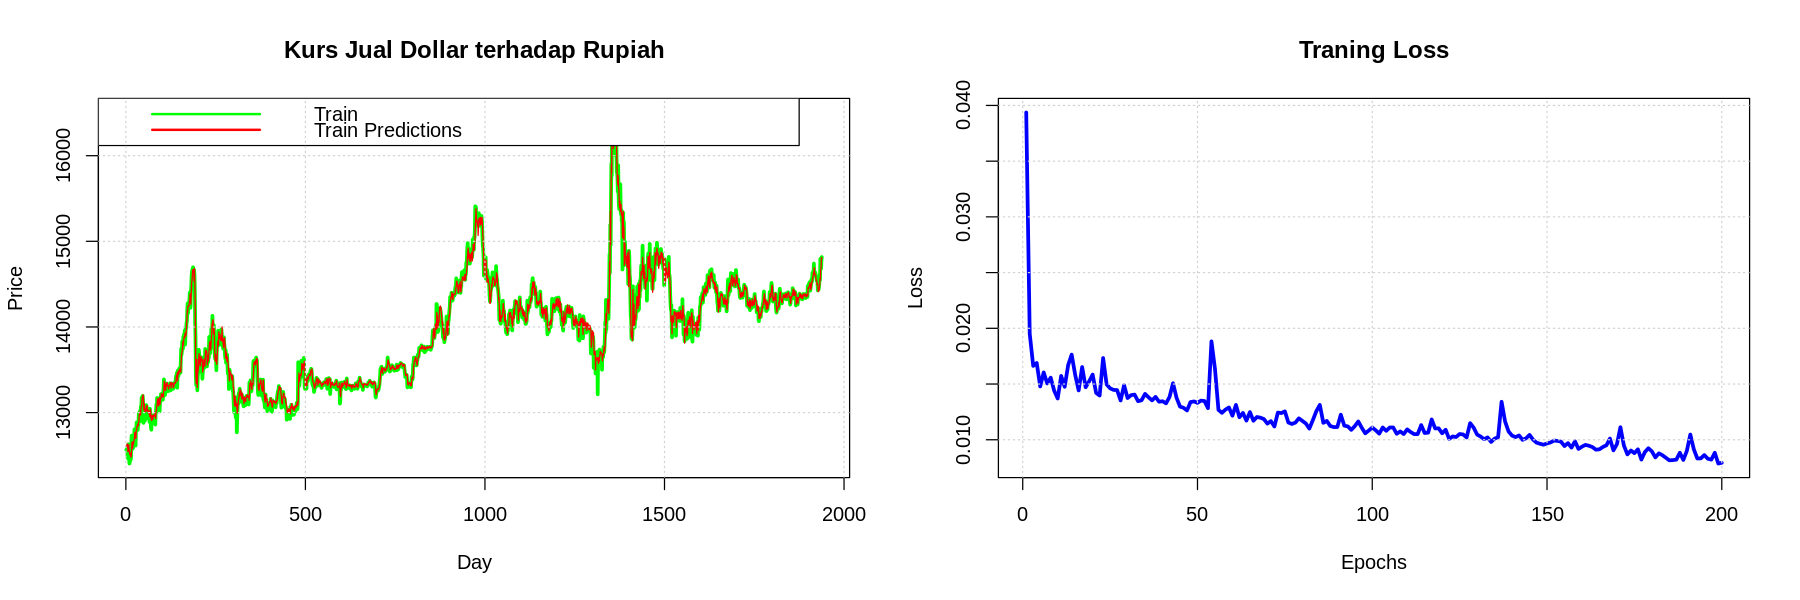

In [ ]:
#plot the predictions from traning data and train Loss
# Set up the layout of the plots
par(mfrow = c(1, 2))
options(repr.plot.width=15, repr.plot.height=5)
# Plot the training and predicted values
plot(y_train_orig, type = "l",main="Kurs Jual Dollar terhadap Rupiah", col = "green", xlab = "Day", ylab = "Price", lwd=3)
lines(y_train_orig, col = "green")
lines(y_train_pred_orig, col = "red")
legend(x = "topleft", legend = c("Train", "Train Predictions"), col = c("green", "red"), lwd = 2)
grid()
# Plot the loss of training data
plot(history$metrics$loss, type = "l",main="Traning Loss", xlab = "Epochs", ylab = "Loss", col = "blue",lwd=3)
grid()

In [ ]:
# Shift the predicted values to start from where the training data predictions end
shift <- length(y_train_pred_orig)
y_test_pred_orig_shifted <- c(rep(NA, shift), y_test_pred_orig[,1])

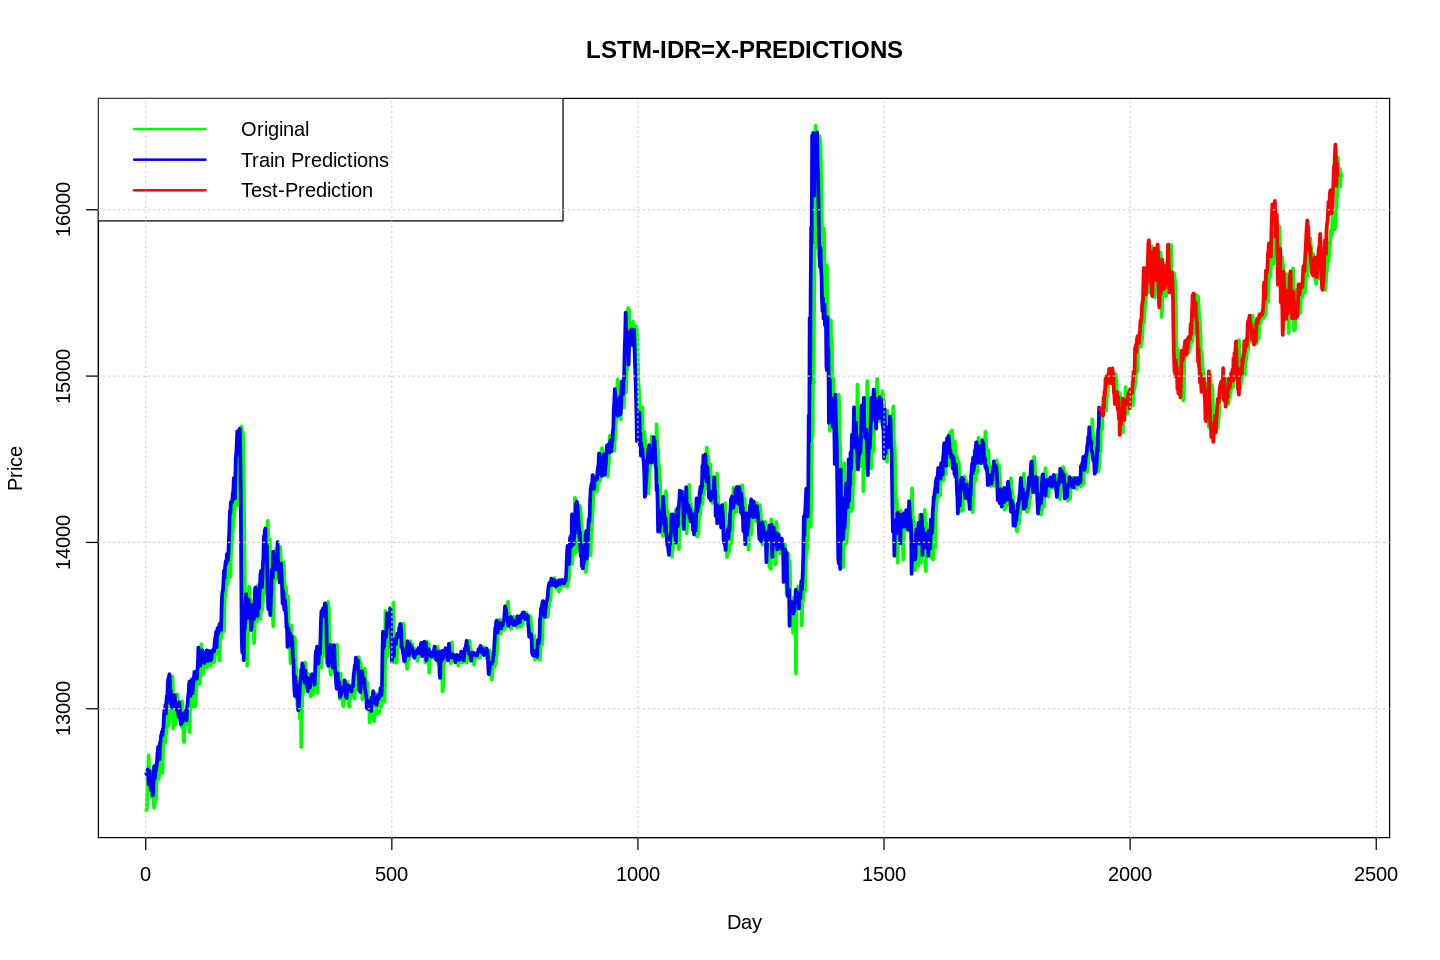

In [ ]:
# Plot the training and predicted values
options(repr.plot.width=12, repr.plot.height=8)
plot(cleaned_data, type = "l", main="LSTM-IDR=X-PREDICTIONS",col = "green", xlab = "Day", ylab = "Price",lwd=3)
lines(y_train_pred_orig, col = "blue",lwd=3)
lines(y_test_pred_orig_shifted, col = "red",lwd=3)
legend(x = "topleft", legend = c("Original", "Train Predictions","Test-Prediction"), col = c("green","blue" ,"red"), lwd = 2)
grid()

In [ ]:
# Menghitung selisih antara prediksi dan nilai sebenarnya
errors1 <- y_train_orig - y_train_pred_orig
errors2 <- y_test_orig - y_test_pred_orig

# Menghitung MSE
mse1 <- mean(errors1^2)
mse2 <- mean(errors2^2)
mse <- (mse1 + mse2) / 2

# Menghitung RMSE
rmse <- sqrt(mse)
rmse

[1] 80.29161

# Hasil Peramalan

| Metode | RMSE
|------|------|
| Naive | 357.9345 |
| Single Moving Average   | 410.1996 |
| Double Moving Average | 502.3871 |
| Simple Exponential Smoothing | 355.3265 |
| Double Exponential Smoothing (2 Paramater Holt) | 375.4497 |
| Triple Exponential Smoothing (Winter Multiplicative) | 415.0726 |
| Klasifikasi Pegels | 515.2677 |
| ARIMA | 327.6876 |
| ARCH/GARCH | 322.2372 |
| **Long Short-Term Memory** | **80.2916**|